In [1]:
%matplotlib ipympl
from mpl_toolkits.mplot3d import axes3d
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.font_manager import FontProperties
from scipy.special import genlaguerre    #genlaguerre(n, alpha)
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.pyplot import MultipleLocator

from matplotlib.lines import Line2D
import ipywidgets as widgets
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.ticker as ticker
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import ipywidgets as widgets
from IPython.display import display
import imageio_ffmpeg

In [2]:
# ===============================================================
# 1. 基本物理常數
# ===============================================================
c = 299792458                 # 光速 (m/s)
hbar = 6.582119569e-16        # 普朗克常數 (eV·s)
pi = 3.141592653589793        # 圓周率

# ===============================================================
# 2. 材料與幾何參數
# ===============================================================
Eg = 1.7                      # 帶隙 Energy gap (eV)
D_B = 1.89e-20                # μm·C
D_G = 0.12e-20                # μm·C
a_0 = 1.0                     # V·s
Q_c = 8.6                     # 切斷波矢 (μm^-1)

# 雷射與波束參數
Lambda = 0.532                # 波長 (μm)
W = 1.5                       # 束腰寬度 Beam waist (μm)
W_2= 1.5                      # 束腰寬度 Beam waist (μm) (程式區分用)
# ===============================================================
# 3. 導出物理量計算
# ===============================================================
q_0 = 2 * pi / Lambda         # 基本波矢 (μm^-1)
q = q_0                       # 特徵波矢 (μm^-1)
ZR = 0.5 * q_0 * (W**2)       # 瑞利距離 Rayleigh range (μm)

# 頻率計算 (轉為 SI 單位 m^-1 後計算角頻率)
w_rad = c * (q_0 * 1e6)       # 角頻率 (s^-1)
w_THz = w_rad / 1e12          # 頻率 (THz)

# ===============================================================
# 4. 結果輸出
# ===============================================================
print(f"q  = {q:.4f} μm^-1")
print(f"w  = {w_THz:.4f} THz ({w_rad:.4e} s^-1)")
print(f"ZR = {ZR:.4f} μm")
print(f"λ  = {2 * pi / q:.4f} μm")

def Factorial(n):
    f=1
    for i in range(1,n+1,1):
        f*=i 
    return f

def Laguerre(rho,l,p):
    l = np.abs(l)
    L = 0
    for m in range(p+1):
        L += (-1)**m * Factorial(l+p) / (Factorial(p-m)*Factorial(l+m)*Factorial(m)) * (2*(rho/W)**2)**m
    return L

def f(rho,l,p):
    l = np.abs(l)
    f = np.sqrt((Factorial(p)*2)/(np.pi*Factorial(l+p))) * np.exp(-(rho/W)**2) * (np.sqrt(2)*rho/W)**l * Laguerre(rho,l,p)
    return f 
    
def u(phi,rho,l,p):
    u = f(rho,l,p) * np.exp(complex(0,1)*l*phi)
    return u

q  = 11.8105 μm^-1
w  = 3540.6984 THz (3.5407e+15 s^-1)
ZR = 13.2868 μm
λ  = 0.5320 μm


# Transverse光場偏振

In [3]:
import numpy as np
from scipy.constants import c

# ===============================================================
# 核心 VVB 橫向偏振場物理公式 (Ax, Ay)
# ===============================================================
def Factorial_safe_2(n):
    """計算階乘，防止 Deprecation 警告"""
    n = int(np.abs(n))
    if n <= 0:
        return 1.0
    val = 1.0
    for i in range(1, n + 1):
        val *= i
    return float(val)

def F_2(phiq_val, q_val, l):
    """Laguerre-Gaussian 徑向與軌道角動量振幅分量"""
    abs_l = int(np.abs(l))
    F_val = (np.sqrt(2 * np.pi / Factorial_safe_2(abs_l)) * 
             W_2**2 * (q_val * W_2 / np.sqrt(2))**abs_l * 
             np.exp(-q_val**2 * W_2**2 / 4))
    return F_val

def G_2(phiq_val, q_val, l1, l2, beta):
    """VVB 疊加場 G 分量"""
    return (np.cos(beta/2) * F_2(phiq_val, q_val, l1) + np.sin(beta/2) * F_2(phiq_val, q_val, l2))

def H_2(phiq_val, q_val, l1, l2, beta):
    """VVB 疊加場 H 分量"""
    return (np.cos(beta/2) * F_2(phiq_val, q_val, l1) - np.sin(beta/2) * F_2(phiq_val, q_val, l2))

def VVBx_2(phiq_val, q_val, l1, l2, beta, alpha):
    """橫向偏振場 X 分量 (ux)"""
    Dl = l2 - l1
    Dlbar = np.abs(l2) - np.abs(l1)
    Tl = (l2 + l1) / 2
    Tlbar = (np.abs(l2) + np.abs(l1)) / 2
    
    g_part = G_2(phiq_val, q_val, l1, l2, beta)
    h_part = H_2(phiq_val, q_val, l1, l2, beta)
    
    ux = (np.cos(Dl/2 * phiq_val - np.pi/4 * Dlbar + alpha/2) * g_part - 
          1j * np.sin(Dl/2 * phiq_val - np.pi/4 * Dlbar + alpha/2) * h_part)
    
    ux = 0.5 * np.exp(1j * Tl * phiq_val) * np.exp(1j * (-np.pi/2 * Tlbar + alpha/2)) * ux
    return ux

def VVBy_2(phiq_val, q_val, sigma1, sigma2, l1, l2, beta, alpha):
    """橫向偏振場 Y 分量 (uy)"""
    Dl = l2 - l1
    Dlbar = np.abs(l2) - np.abs(l1)
    Tl = (l2 + l1) / 2
    Tlbar = (np.abs(l2) + np.abs(l1)) / 2
    
    g_part = G_2(phiq_val, q_val, l1, l2, beta)
    h_part = H_2(phiq_val, q_val, l1, l2, beta)
    
    uy = (np.sin(Dl/2 * phiq_val - np.pi/4 * Dlbar + alpha/2) * g_part + 
          1j * np.cos(Dl/2 * phiq_val - np.pi/4 * Dlbar + alpha/2) * h_part)

    uy = 0.5 * np.exp(1j * Tl * phiq_val) * np.exp(1j * (-np.pi/2 * Tlbar + alpha/2)) * uy
    return uy

def VVB_field_components(phiq_val, q_val, l1, l2, sigma1, sigma2, beta, alpha):
    """主繪圖函式對應接頭：整合回傳 Ax, Ay"""
    Ax = VVBx_2(phiq_val, q_val, l1, l2, beta, alpha)
    Ay = VVBy_2(phiq_val, q_val, sigma1, sigma2, l1, l2, beta, alpha)
    return Ax, Ay

Output()

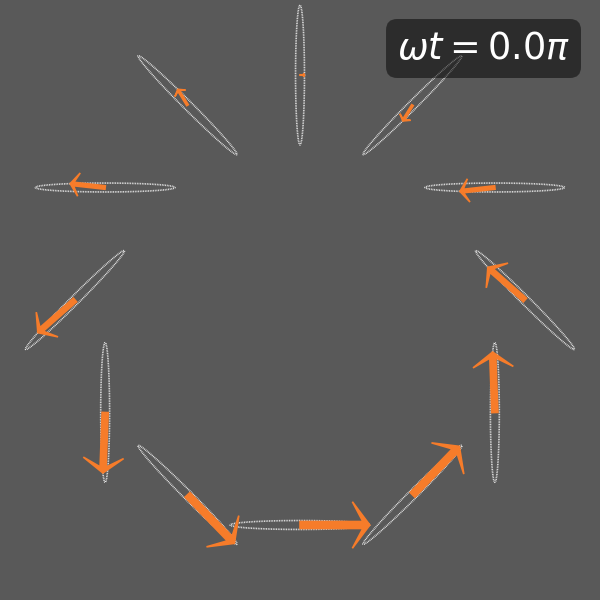

In [4]:
# ===============================================================
# 1. PARAMETERS & INITIAL SETUPS
# ===============================================================
SAVE_DIR = r"H:\Liu\code\Main_code\DoVP_Jena\VVB_transverse"
t_arr_2 = np.arange(0, 2*np.pi, 0.02) 
limit_2 = 0.235 * Q_c
bg_color = (89/255.0, 89/255.0, 89/255.0)

fig_2 = plt.figure(figsize=(5, 5), dpi=120, facecolor=bg_color)

# UI 元件設定
beta_slider_2 = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.02, description='beta (π)')
alpha_slider_2 = widgets.FloatSlider(value=0, min=0, max=2, step=0.02, description='alpha (π)')
wt_slider_2 = widgets.FloatSlider(value=0, min=0, max=2, step=0.01, description='wt (π)') 
sigma1_box_2, sigma2_box_2 = widgets.Dropdown(options=[1, -1], value=1, description='σ1'), widgets.Dropdown(options=[1, -1], value=-1, description='σ2')
l1_box_2, l2_box_2, p_box_2 = widgets.IntText(value=-1, description='l'), widgets.IntText(value=2, description="l'"), widgets.IntText(value=0, description='p')

export_button = widgets.Button(description="匯出單一 MP4", button_style='primary', icon='video-camera')
export_all_button = widgets.Button(description="批次匯出全部 12 個 MP4", button_style='success', icon='film')
status_output = widgets.Output()


# ===============================================================
# 2. UPDATE PLOT FUNCTION
# ===============================================================
def update_plot_full_transverse(l1, l2, sigma1, sigma2, beta, alpha, wt):
    fig_2.clear()
    fig_2.patch.set_facecolor(bg_color)
    
    ax_pol = fig_2.add_axes([0, 0, 1, 1], facecolor=bg_color)
    ax_pol.set_aspect('equal')
    
    beta_rad, alpha_rad, wt_rad = beta * np.pi, alpha * np.pi, wt * np.pi 
    R = 0.75 * limit_2
    
    for ang in np.linspace(0, 2*np.pi, 12, endpoint=False):
        cx, cy = R * np.cos(ang), R * np.sin(ang)
        Ax, Ay = VVB_field_components(ang, R, l1, l2, sigma1, sigma2, beta_rad, alpha_rad)
        a, b = 0.25 * Ax, 0.25 * Ay

        # 繪製偏振軌跡
        ax_pol.plot(cx + np.real(a * np.exp(-1j * t_arr_2)), cy + np.real(b * np.exp(-1j * t_arr_2)), 
                    color='white', dashes=(0.5, 0.5), alpha=0.9, lw=1, zorder=2)

        # 瞬時電場箭頭
        Ex_t, Ey_t = np.real(a * np.exp(-1j * wt_rad)), np.real(b * np.exp(-1j * wt_rad))
        r_len = np.hypot(Ex_t, Ey_t)
        if r_len > 1e-5:
            norm_factor = r_len / (0.03 * limit_2)
            ax_pol.arrow(cx, cy, Ex_t, Ey_t, width=0.003 * limit_2 * norm_factor, head_width=0.02 * limit_2 * norm_factor,
                         head_length=0.25 * r_len, overhang=0.6, length_includes_head=True, color=(246/255.0, 124/255.0, 42/255.0), zorder=3)

    ax_pol.axis('off')
    ax_pol.set_xlim(-limit_2, limit_2)
    ax_pol.set_ylim(-limit_2, limit_2)

    # 右上角 wt 標記 (黑色半透明框)
    ax_pol.text(0.95, 0.95, f"$\omega t = {wt:.1f}\pi$", transform=ax_pol.transAxes, color='white', 
                fontsize=22, fontweight='bold', ha='right', va='top', 
                bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5, edgecolor='none'))


# ===============================================================
# 3. ANIMATION EXPORT LOGIC
# ===============================================================
def render_and_save(l1, l2, sigma1, sigma2, beta, alpha, file_name):
    plt.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()
    anim = animation.FuncAnimation(fig_2, lambda wt: update_plot_full_transverse(l1, l2, sigma1, sigma2, beta, alpha, wt), frames=np.linspace(0, 2, 100), interval=50)
    
    full_path = os.path.join(SAVE_DIR, file_name)
    writer = animation.FFMpegWriter(fps=20, codec='h264', bitrate=1800, extra_args=['-pix_fmt', 'yuv420p', '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2'])
    anim.save(full_path, writer=writer, dpi=120, savefig_kwargs={'facecolor': bg_color, 'bbox_inches': 'tight', 'pad_inches': 0})
    return full_path

def start_export(batch=False):
    with status_output:
        status_output.clear_output()
        os.makedirs(SAVE_DIR, exist_ok=True)
        
        p, s1, s2 = p_box_2.value, sigma1_box_2.value, sigma2_box_2.value
        b_val, a_val = beta_slider_2.value, alpha_slider_2.value
        targets = [(l1_box_2.value, l2_box_2.value)] if not batch else [(l1, l2) for l1 in [-1, 0, 1] for l2 in [-1, 0, 1, 2]]
        
        print(f"🚀 開始渲染 {'批次' if batch else '單一'} 影片，共 {len(targets)} 個檔案...")
        for idx, (l1, l2) in enumerate(targets, 1):
            fname = f"l_{l1}_lp_{l2}.mp4"
            print(f"[{idx}/{len(targets)}] 渲染中: {fname} ...")
            try:
                render_and_save(l1, l2, p, s1, s2, b_val, a_val, fname)
            except Exception as e:
                print(f"❌ {fname} 失敗: {e}")
        print("🎉 任務完成！")

export_button.on_click(lambda b: start_export(batch=False))
export_all_button.on_click(lambda b: start_export(batch=True))


# ===============================================================
# 4. UI DISPLAY
# ===============================================================
out_2 = widgets.interactive_output(update_plot_full_transverse, {
    'l1': l1_box_2, 'l2': l2_box_2, 'sigma1': sigma1_box_2, 'sigma2': sigma2_box_2,
    'beta': beta_slider_2, 'alpha': alpha_slider_2, 'wt': wt_slider_2
})

display(widgets.VBox([
    widgets.Label("### 1. Physics Coefficients ###"), 
    widgets.HBox([sigma1_box_2, sigma2_box_2, l1_box_2, l2_box_2]), 
    widgets.Label("### 2. Space & Time Parameters ###"), 
    widgets.HBox([beta_slider_2, alpha_slider_2, wt_slider_2]),
    widgets.Label("### 3. MP4 Export Control ###"),
    widgets.HBox([export_button, export_all_button]),
    status_output
]), out_2)

# Longitudinal光場(實部)

In [5]:
Lambda = 0.532 #um
q_0 = 2*np.pi/Lambda # um-1
w = c*q_0*10**(-6)
W = 1.5 #um
ZR = 1/2 * q_0 * (W**2) # um-1
Qc = 8.6 #um-1
print(q_0, w, ZR)

def F(phiq,q,l):
    # F = (-complex(0,1))**np.abs(l)*np.sqrt(2*np.pi/Factorial(np.abs(l))) * W**2 * (q*W/np.sqrt(2))**np.abs(l) * np.exp(-q**2*W**2/4) 
    F = np.sqrt(2*np.pi/Factorial(np.abs(l))) * W**2 * (q*W/np.sqrt(2))**np.abs(l) * np.exp(-q**2*W**2/4) 
    return F

def VVBuz(phiq,q,sigma1,sigma2,l1,l2,beta,alpha, wt):
    
    DJ = l2-l1+sigma2-sigma1
    TJ = (l2+l1+sigma2+sigma1)/2
    Dabsl = np.abs(l2)-np.abs(l1)
    Tabsl = (np.abs(l2)+np.abs(l1))/2
    
    VVBuz = np.cos(TJ*phiq-np.pi*Tabsl/2+alpha/2-wt)*np.cos((DJ*phiq+alpha-np.pi*Dabsl/2)/2)*(np.cos(beta/2)*F(phiq,q,l1)+np.sin(beta/2)*F(phiq,q,l2))  -  np.sin(TJ*phiq-np.pi*Tabsl/2+alpha/2-wt)*np.cos((DJ*phiq+alpha-np.pi*Dabsl/2+np.pi)/2)*(np.cos(beta/2)*F(phiq,q,l1)-np.sin(beta/2)*F(phiq,q,l2))
    # VVBuz = np.cos(TJ*phiq-np.pi*Tabsl/2+alpha/2-wt)*np.cos((DJ*phiq+alpha-np.pi*Dabsl/2)/2)*(np.cos(beta/2)*F(phiq,q,l1)+np.sin(beta/2)*F(phiq,q,l2))
    # VVBuz = - np.sin(TJ*phiq-np.pi*Tabsl/2+alpha/2-wt)*np.cos((DJ*phiq+alpha-np.pi*Dabsl/2+np.pi)/2)*(np.cos(beta/2)*F(phiq,q,l1)-np.sin(beta/2)*F(phiq,q,l2))*5
    
    VVBuz = -1/np.sqrt(2)* (q/np.sqrt(q**2+q_0**2)) * VVBuz
    VVBuz = np.real(VVBuz)
    # VVBuz = np.imag(VVBuz)
    return VVBuz

print('T=2*pi/w=',2*np.pi/w)

11.810498697705988 3540.698434791077 13.286811034919236
T=2*pi/w= 0.0017745609864541691


Output()

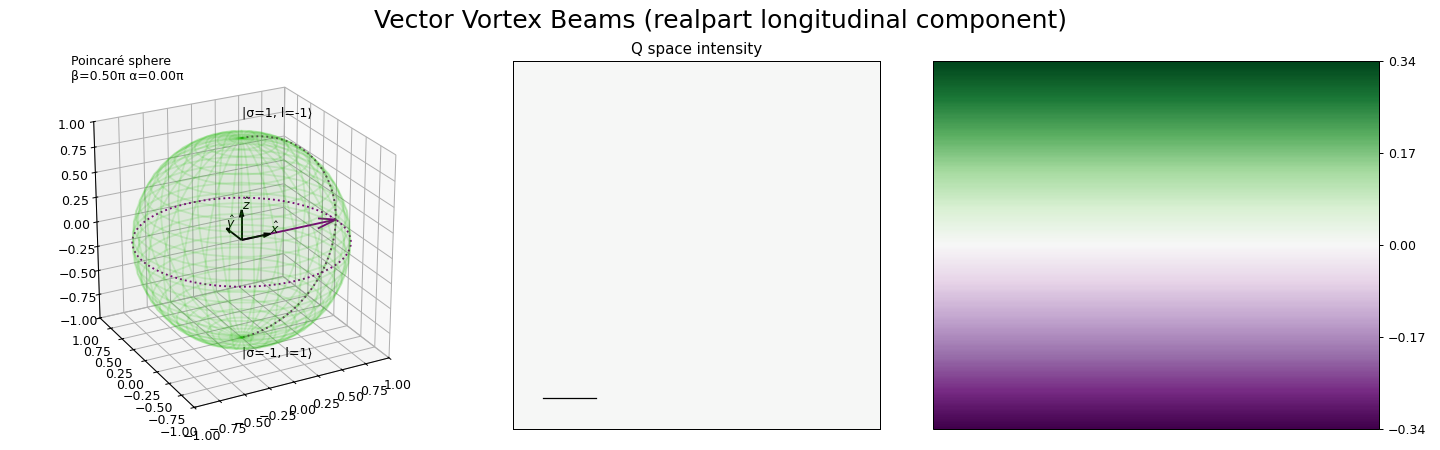

In [6]:
# ===============================================================
# 1. PARAMETERS & INITIAL SETUPS (完全隔離的變數命名)
# ===============================================================
W, sigma1, sigma2 = 1.5, 1, -1
# 全域時間軌跡改為 t_arr_3，避免與滑桿數值 wt 衝突
t_arr_3 = np.arange(0, 2*np.pi, 0.02)
circle, polar = np.linspace(0, 2*np.pi, 200), np.linspace(0, np.pi, 200)

# Mesh for intensity map
q, phiq = np.meshgrid(np.linspace(0.001, 6, 200), np.linspace(0, 2*np.pi, 200))
X, Y = q*np.cos(phiq), q*np.sin(phiq)

# Sphere mesh
U, V = np.mgrid[0:2*np.pi:30j, 0:np.pi:30j]
sx, sy, sz = np.cos(U)*np.sin(V), np.sin(U)*np.sin(V), np.cos(V)

# Layout & Widgets (變數名稱加上 _3 隔離)
fig_3 = plt.figure(figsize=(16,5), dpi=90)

beta_slider_3 = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.02, description='beta (π)')
alpha_slider_3 = widgets.FloatSlider(value=0, min=0, max=2, step=0.02, description='alpha (π)')
wt_slider_3 = widgets.FloatSlider(value=0, min=0, max=2, step=2/1000, description='wt (π)')
l1_box_3, l2_box_3 = widgets.IntText(value=-1, description='l'), widgets.IntText(value=1, description="l'")

LIMIT = 0.34

# ===============================================================
# 2. UPDATE PLOT (函數名稱改為 update_plot_3，參數統一使用 wt)
# ===============================================================
def update_plot_3(l1, l2, beta, alpha, wt):
    
    # 物理相位轉換：將滑桿 wt (單位: π) 轉成弧度 wt_rad
    wt_rad = wt * np.pi
    
    beta, alpha = beta * np.pi, alpha * np.pi
    
    # 徹底清除舊圖記憶，防止 3D quiver 與導引圓縮放異常
    fig_3.clear()
    
    # 重新建立子圖 (1, 3, i)
    ax3D = fig_3.add_subplot(1, 3, 1, projection='3d')
    ax_int = fig_3.add_subplot(1, 3, 2)
    cax = fig_3.add_subplot(1, 3, 3)
    
    ax3D.set_aspect('equal')
    ax_int.set_aspect('equal')

    # ===================================================
    # 1. Poincaré sphere
    # ===================================================
    ax3D.plot_wireframe(sx, sy, sz, color=(0.15,0.8,0.05,0.15))
    ax3D.plot_surface(sx, sy, sz, color=(0.15,0.8,0.05,0.05))
    
    qx, qy, qz = np.cos(alpha)*np.sin(beta), np.sin(alpha)*np.sin(beta), np.cos(beta)
    
    # 標示偏振態向量，限制箭頭比例 (arrow_length_ratio)
    ax3D.quiver(0, 0, 0, qx, qy, qz, color='purple', arrow_length_ratio=0.2)
    
    # 畫出三個標準黑色坐標軸
    for mx, my, mz in [(0.3, 0, 0), (0, 0.3, 0), (0, 0, 0.3)]:
        ax3D.quiver(0, 0, 0, mx, my, mz, color='k', arrow_length_ratio=0.25)

    ax3D.plot(np.sin(beta)*np.cos(circle), np.sin(beta)*np.sin(circle), np.cos(beta)+0*circle, linestyle='dotted', color='purple')
    ax3D.plot(np.sin(polar)*np.cos(alpha), np.sin(polar)*np.sin(alpha), np.cos(polar), linestyle='dotted', color='purple')

    ax3D.text2D(0.05, 0.95, f'Poincaré sphere\nβ={beta/np.pi:.2f}π α={alpha/np.pi:.2f}π', transform=ax3D.transAxes)
    for txt, (mx, my, mz) in {r'$\hat{x}$':(0.3,0,0), r'$\hat{y}$':(0,0.3,0), r'$\hat{z}$':(0,0,0.3)}.items(): ax3D.text(mx, my, mz, txt)
    ax3D.text(0, 0, 1.2, f'|σ={sigma1}, l={l1}⟩')
    ax3D.text(0, 0, -1.2, f'|σ={sigma2}, l={l2}⟩')
    ax3D.set_xlim(-1,1); ax3D.set_ylim(-1,1); ax3D.set_zlim(-1,1); ax3D.view_init(24, -118)

    # ===================================================
    # 2. Intensity (Longitudinal component: VVBuz, Blues 色階)
    # ===================================================
    # 將轉換後的瞬時相位 wt_rad 傳入 VVBuz 函數中
    I = VVBuz(phiq, q, sigma1, sigma2, l1, l2, beta, alpha, wt_rad)
    
    TJ = (l2+l1+sigma2+sigma1)/2
    print('TJ =', TJ)
    
    contour = ax_int.contourf(X, Y, I, levels=np.linspace(-LIMIT, LIMIT, 300), cmap='PRGn')
    ax_int.add_line(Line2D(np.linspace(-2.5, -2.5+0.86, 50), np.linspace(-2.5, -2.5, 50), linewidth=1, color='black'))
    ax_int.set_title("Q space intensity"); ax_int.set_xticks([]); ax_int.set_yticks([]); ax_int.set_xlim(-3,3); ax_int.set_ylim(-3,3)

    plt.colorbar(contour, cax=cax, ticks=np.linspace(-LIMIT, LIMIT, 5))
    
    plt.suptitle("Vector Vortex Beams (realpart longitudinal component)", fontsize=20)
    plt.tight_layout()
    print(f'alpha={alpha/np.pi:.3f}π   beta={beta/np.pi:.3f}π   wt={wt:.2f}π')

# ===============================================================
# 3. UI 聯動與顯示 (綁定 update_plot_3 與帶有 _3 後綴的滑桿)
# ===============================================================
out_3 = widgets.interactive_output(update_plot_3, {
    'l1': l1_box_3, 
    'l2': l2_box_3, 
    'beta': beta_slider_3, 
    'alpha': alpha_slider_3, 
    'wt': wt_slider_3 # 確保此處 key 與 update_plot_3 的參數名 wt 完全一致
})

ui_3 = widgets.VBox([
    widgets.Label("coefficient"), 
    widgets.HBox([l1_box_3, l2_box_3]), 
    widgets.Label("parameter"), 
    widgets.HBox([beta_slider_3, alpha_slider_3, wt_slider_3])
])

display(ui_3, out_3)

Output()

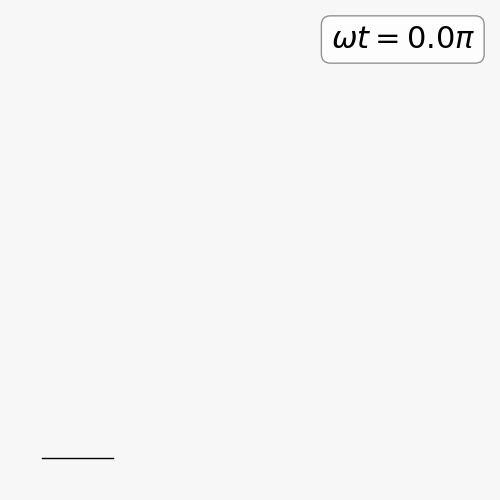

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import ipywidgets as widgets
from IPython.display import display
from matplotlib.lines import Line2D
import imageio_ffmpeg

# ===============================================================
# 1. PARAMETERS & INITIAL SETUPS
# ===============================================================
W, sigma1, sigma2 = 1.5, 1, -1

# 指定 MP4 匯出的目標資料夾絕對路徑
SAVE_DIR = r"H:\Liu\code\Main_code\DoVP_Jena\VVB_transverse"

# Mesh for intensity map
q, phiq = np.meshgrid(np.linspace(0.001, 6, 200), np.linspace(0, 2*np.pi, 200))
X, Y = q*np.cos(phiq), q*np.sin(phiq)

# Layout & Widgets (5x5 正方形尺寸)
fig_3 = plt.figure(figsize=(5, 5), dpi=100)

beta_slider_3 = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.02, description='beta (π)')
alpha_slider_3 = widgets.FloatSlider(value=0, min=0, max=2, step=0.02, description='alpha (π)')
wt_slider_3 = widgets.FloatSlider(value=0, min=0, max=2, step=2/1000, description='wt (π)')
l1_box_3, l2_box_3 = widgets.IntText(value=-1, description='l'), widgets.IntText(value=1, description="l'")

# 動態匯出控制按鈕
export_button = widgets.Button(description="匯出單一 MP4", button_style='primary', icon='video-camera')
export_all_button = widgets.Button(description="批次匯出全部 12 個 MP4", button_style='success', icon='film')
status_output = widgets.Output()

LIMIT = 0.34

# ===============================================================
# 2. UPDATE PLOT (無標題、無邊界留白、右上角 wt 顯示至小數點一位)
# ===============================================================
def update_plot_3(l1, l2, beta, alpha, wt):
    wt_rad = wt * np.pi
    beta_rad, alpha_rad = beta * np.pi, alpha * np.pi
    
    fig_3.clear()
    
    # 讓座標軸完全填滿整個 figure 畫布
    ax_int = fig_3.add_axes([0, 0, 1, 1])
    ax_int.set_aspect('equal')

    # Intensity (Longitudinal component)
    I = VVBuz(phiq, q, sigma1, sigma2, l1, l2, beta_rad, alpha_rad, wt_rad)
    
    contour = ax_int.contourf(X, Y, I, levels=np.linspace(-LIMIT, LIMIT, 300), cmap='PRGn')
    ax_int.add_line(Line2D(np.linspace(-2.5, -2.5+0.86, 50), np.linspace(-2.5, -2.5, 50), linewidth=1, color='black'))
    
    # 關閉座標軸標籤與邊框
    ax_int.axis('off')
    ax_int.set_xlim(-3, 3)
    ax_int.set_ylim(-3, 3)

    # 在右上角添加 wt 文字標註 (.1f 顯示小數點一位)
    ax_int.text(0.95, 0.95, f'$\omega t = {wt:.1f}\pi$', transform=ax_int.transAxes,
                color='black', fontsize=22, fontweight='bold',
                ha='right', va='top',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray'))

# 核心動畫渲染與儲存輔助函數
def render_and_save(l1, l2, beta, alpha, file_name):
    wt_frames = np.linspace(0, 2, 100)
    
    def animate(frame_wt):
        update_plot_3(l1, l2, beta, alpha, frame_wt)
    
    anim = animation.FuncAnimation(fig_3, animate, frames=wt_frames, interval=50)
    ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
    full_path = os.path.join(SAVE_DIR, file_name)
    
    writer = animation.FFMpegWriter(
        fps=20, 
        codec='h264', 
        bitrate=1800,
        extra_args=['-pix_fmt', 'yuv420p', '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2']
    )
    plt.rcParams['animation.ffmpeg_path'] = ffmpeg_exe
    anim.save(full_path, writer=writer, dpi=120, savefig_kwargs={'bbox_inches': 'tight', 'pad_inches': 0})
    return full_path

# ===============================================================
# 3. EXPORT ANIMATION FUNCTIONS (單一匯出 & 批次匯出)
# ===============================================================
def export_animation(b):
    with status_output:
        status_output.clear_output()
        if not os.path.exists(SAVE_DIR):
            os.makedirs(SAVE_DIR)
            
        l1, l2 = l1_box_3.value, l2_box_3.value
        beta, alpha = beta_slider_3.value, alpha_slider_3.value
        file_name = f"l_{l1}_lp_{l2}.mp4"
        
        print(f"🎬 正在渲染單一動畫: {file_name} ...")
        try:
            full_path = render_and_save(l1, l2, beta, alpha, file_name)
            print(f"✅ 匯出成功！路徑：{full_path}")
        except Exception as e:
            print(f"⚠️ 匯出失敗，錯誤訊息: {e}")

def export_all_animations(b):
    with status_output:
        status_output.clear_output()
        if not os.path.exists(SAVE_DIR):
            os.makedirs(SAVE_DIR)
            
        l1_list = [-1, 0, 1]
        l2_list = [-1, 0, 1, 2]
        beta = beta_slider_3.value
        alpha = alpha_slider_3.value
        
        total = len(l1_list) * len(l2_list)
        current = 0
        
        print(f"🚀 開始批次渲染全部 {total} 個影片...")
        print(f"目標資料夾：{SAVE_DIR}\n" + "-"*40)
        
        for l1 in l1_list:
            for l2 in l2_list:
                current += 1
                file_name = f"l_{l1}_lp_{l2}_longitudinal.mp4"
                print(f"[{current}/{total}] 正在渲染 {file_name} ...")
                try:
                    render_and_save(l1, l2, beta, alpha, file_name)
                except Exception as e:
                    print(f"❌ {file_name} 渲染失敗: {e}")
        
        print("-" * 40)
        print(f"🎉 全部 {total} 個 MP4 影片已順利匯出至資料夾！")

export_button.on_click(export_animation)
export_all_button.on_click(export_all_animations)

# ===============================================================
# 4. UI 聯動與顯示
# ===============================================================
out_3 = widgets.interactive_output(update_plot_3, {
    'l1': l1_box_3, 
    'l2': l2_box_3, 
    'beta': beta_slider_3, 
    'alpha': alpha_slider_3, 
    'wt': wt_slider_3
})

ui_3 = widgets.VBox([
    widgets.Label("coefficient"), 
    widgets.HBox([l1_box_3, l2_box_3]), 
    widgets.Label("parameter"), 
    widgets.HBox([beta_slider_3, alpha_slider_3, wt_slider_3]),
    widgets.HBox([export_button, export_all_button]),
    status_output
])

display(ui_3, out_3)

# Longitudinal光場(絕對值)

In [8]:
Lambda = 0.532 #um
q_0 = 2*np.pi/Lambda # um-1
w = c*q_0*10**(-6)
W = 1.5 #um
ZR = 1/2 * q_0 * (W**2) # um-1
Qc = 8.6 #um-1
print(q_0, w, ZR)

def F(phiq,q,l):
    F = (-complex(0,1))**np.abs(l)*np.sqrt(2*np.pi/Factorial(np.abs(l))) * W**2 * (q*W/np.sqrt(2))**np.abs(l) * np.exp(-q**2*W**2/4) 
    # F = np.sqrt(2*np.pi/Factorial(np.abs(l))) * W**2 * (q*W/np.sqrt(2))**np.abs(l) * np.exp(-q**2*W**2/4) 
    return F

def VVBuz(phiq,q,sigma1,sigma2,l1,l2,beta,alpha):
    
    DJ = l2-l1+sigma2-sigma1
    TJ = (l2+l1+sigma2+sigma1)/2
    
    VVBuz = np.cos((DJ*phiq+alpha)/2)*(np.cos(beta/2)*F(phiq,q,l1)+np.sin(beta/2)*F(phiq,q,l2))  +  complex(0,1)*np.cos((DJ*phiq+alpha+np.pi)/2)*(np.cos(beta/2)*F(phiq,q,l1)-np.sin(beta/2)*F(phiq,q,l2))
    # VVBuz = np.cos((DJ*phiq+alpha)/2)*(np.cos(beta/2)*F(phiq,q,l1)+np.sin(beta/2)*F(phiq,q,l2))  
    # VVBuz = complex(0,1)*np.cos((DJ*phiq+alpha+np.pi)/2)*(np.cos(beta/2)*F(phiq,q,l1)-np.sin(beta/2)*F(phiq,q,l2))
    
    VVBuz = -1/np.sqrt(2)* (q/np.sqrt(q**2+q_0**2))*np.exp(complex(0,1)*(TJ*phiq+alpha/2)) *VVBuz
    VVBuz = np.abs(VVBuz)**2
    return VVBuz

11.810498697705988 3540.698434791077 13.286811034919236


Output()

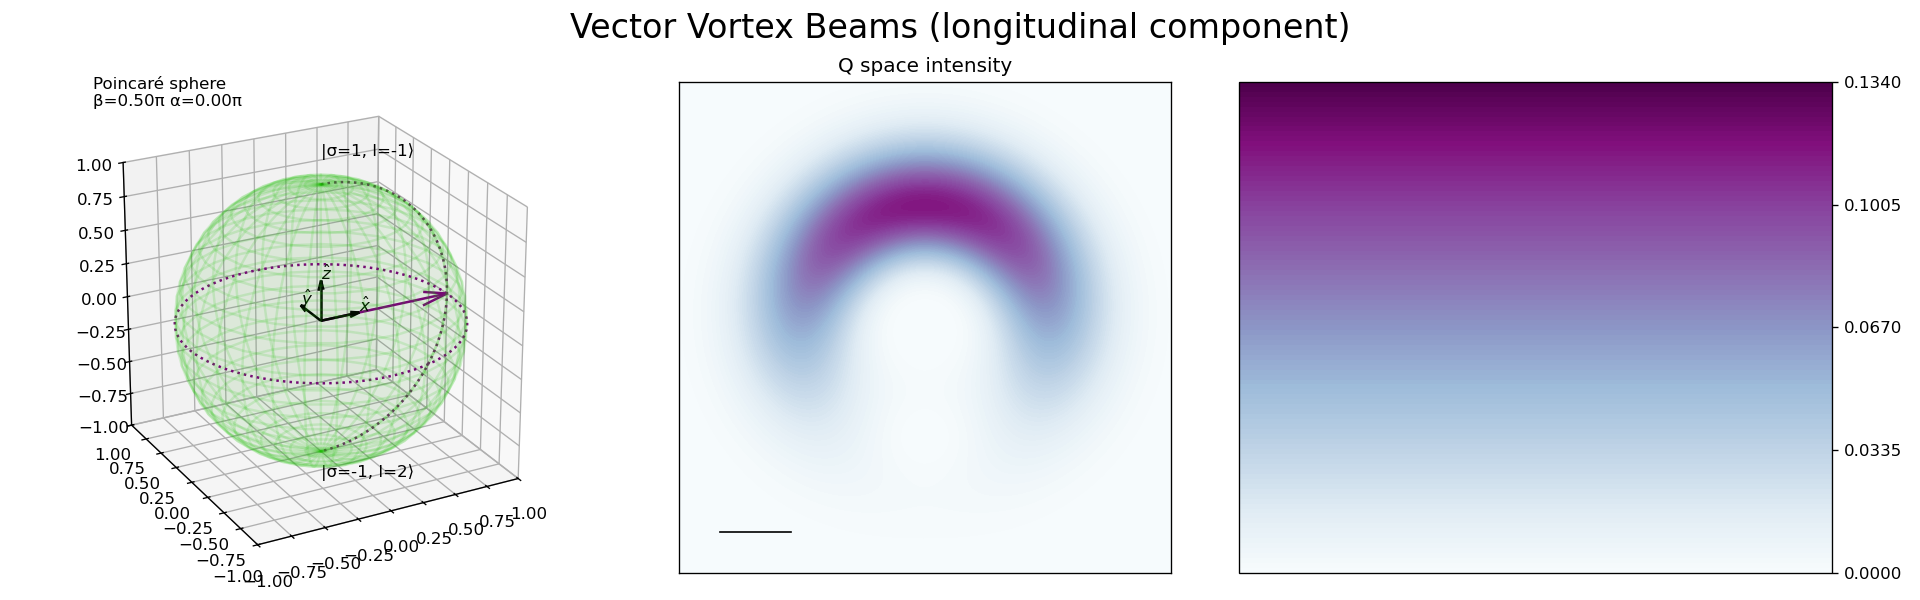

In [9]:
W, sigma1, sigma2 = 1.5, 1, -1
t = np.arange(0, 2*np.pi, 0.02)
circle, polar = np.linspace(0, 2*np.pi, 100), np.linspace(0, np.pi, 100)

# Mesh for intensity map
q, phiq = np.meshgrid(np.linspace(0.001, 6, 200), np.linspace(0, 2*np.pi, 200))
X, Y = q*np.cos(phiq), q*np.sin(phiq)

# Sphere mesh
U, V = np.mgrid[0:2*np.pi:30j, 0:np.pi:30j]
sx, sy, sz = np.cos(U)*np.sin(V), np.sin(U)*np.sin(V), np.cos(V)

# Layout & Widgets
fig = plt.figure(figsize=(16,5), dpi=120)

beta_slider = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.02, description='beta (π)')
alpha_slider = widgets.FloatSlider(value=0, min=0, max=2, step=0.02, description='alpha (π)')
l1_box, l2_box, p_box = widgets.IntText(value=-1, description='l'), widgets.IntText(value=2, description="l'"), widgets.IntText(value=0, description='p')

def update_plot(l1, l2, p, beta, alpha):
    beta, alpha = beta * np.pi, alpha * np.pi
    
    # 徹底清除舊圖記憶，防止 3D quiver 與導引圓縮放異常
    fig.clear()
    
    # 重新建立子圖 (1, 3, i)
    ax3D = fig.add_subplot(1, 3, 1, projection='3d')
    ax_int = fig.add_subplot(1, 3, 2)
    cax = fig.add_subplot(1, 3, 3)
    
    ax3D.set_aspect('equal')
    ax_int.set_aspect('equal')

    # ===================================================
    # 1. Poincaré sphere
    # ===================================================
    ax3D.plot_wireframe(sx, sy, sz, color=(0.15,0.8,0.05,0.15))
    ax3D.plot_surface(sx, sy, sz, color=(0.15,0.8,0.05,0.05))
    
    qx, qy, qz = np.cos(alpha)*np.sin(beta), np.sin(alpha)*np.sin(beta), np.cos(beta)
    
    # 標示偏振態向量，限制箭頭比例 (arrow_length_ratio)
    ax3D.quiver(0, 0, 0, qx, qy, qz, color='purple', arrow_length_ratio=0.2)
    
    # 畫出三個標準黑色坐標軸
    for mx, my, mz in [(0.3, 0, 0), (0, 0.3, 0), (0, 0, 0.3)]:
        ax3D.quiver(0, 0, 0, mx, my, mz, color='k', arrow_length_ratio=0.25)

    # 修正：使用正確的 'dotted' 純虛線樣式，無 'p' 標記
    ax3D.plot(np.sin(beta)*np.cos(circle), np.sin(beta)*np.sin(circle), np.cos(beta)+0*circle, linestyle='dotted', color='purple')
    ax3D.plot(np.sin(polar)*np.cos(alpha), np.sin(polar)*np.sin(alpha), np.cos(polar), linestyle='dotted', color='purple')

    ax3D.text2D(0.05, 0.95, f'Poincaré sphere\nβ={beta/np.pi:.2f}π α={alpha/np.pi:.2f}π', transform=ax3D.transAxes)
    for txt, (mx, my, mz) in {r'$\hat{x}$':(0.3,0,0), r'$\hat{y}$':(0,0.3,0), r'$\hat{z}$':(0,0,0.3)}.items(): ax3D.text(mx, my, mz, txt)
    ax3D.text(0, 0, 1.2, f'|σ={sigma1}, l={l1}⟩'); ax3D.text(0, 0, -1.2, f'|σ={sigma2}, l={l2}⟩')
    ax3D.set_xlim(-1,1); ax3D.set_ylim(-1,1); ax3D.set_zlim(-1,1); ax3D.view_init(24, -118)

    # ===================================================
    # 2. Intensity (Longitudinal component: VVBuz, Blues 色階)
    # ===================================================
    I = VVBuz(phiq, q, sigma1, sigma2, l1, l2, beta, alpha)
    
    TJ = (l2+l1+sigma2+sigma1)/2
    print('TJ=',TJ)

    contour = ax_int.contourf(X, Y, I, levels=np.linspace(0, 0.134, 100), cmap='BuPu')
    # contour = ax_int.contourf(X, Y, I, levels=np.linspace(0, 0.134, 100), cmap='YlGn')
    # contour = ax_int.contourf(X, Y, I, levels=np.linspace(0, 0.0067, 100), cmap='PuRd')
    ax_int.add_line(Line2D(np.linspace(-2.5, -2.5+0.86, 50), np.linspace(-2.5, -2.5, 50), linewidth=1, color='black'))
    ax_int.set_title("Q space intensity"); ax_int.set_xticks([]); ax_int.set_yticks([]); ax_int.set_xlim(-3,3); ax_int.set_ylim(-3,3)

    plt.colorbar(contour, cax=cax, ticks=np.linspace(0, 0.134, 5))
    
    plt.suptitle("Vector Vortex Beams (longitudinal component)", fontsize=20)
    plt.tight_layout()
    print(f'alpha={alpha/np.pi:.3f}π   beta={beta/np.pi:.3f}π')

out = widgets.interactive_output(update_plot, {'l1':l1_box, 'l2':l2_box, 'p':p_box, 'beta':beta_slider, 'alpha':alpha_slider})
ui = widgets.VBox([widgets.Label("coefficient"), widgets.HBox([l1_box, l2_box, p_box]), widgets.Label("parameter"), widgets.HBox([beta_slider, alpha_slider])])
display(ui, out)

# 自訂colormap

In [10]:
import numpy as np
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# ===============================================================
# 獨立 COLORMAPS 設定區塊
# ===============================================================
ncolors = 1001  # 用奇數可以讓雙極性的 0.0 完美落在正中間的那點

# --- 【雙極性專用】數值範圍從 -1 到 1，值為 0 時是黑色 ---
ncolor_div = np.linspace(-1, 1, ncolors)
pos_mask = ncolor_div >= 0
neg_mask = ncolor_div < 0

factor_pos = ncolor_div[pos_mask]**1.5
factor_neg = np.abs(ncolor_div[neg_mask])**1.5

# 🎯 將雙極性 Alpha 固定為完全不透明 (1.0)
A_div = np.ones(ncolors)


# --- 【單向性專用：3 (B)】數值範圍從 0 到 1，維持原本從白出發 ---
ncolor_seq = np.linspace(0, 1, ncolors)
# 🎯 將單向性 Alpha 固定為完全不透明 (1.0)
A_seq = np.ones(ncolors)


# ===============================================================
# 建立與配置各組 Colormap 的顏色矩陣 (0=R, 1=G, 2=B)
# ===============================================================

def create_div_array(pos_rgb, neg_rgb):
    """輔助函式：快速生成雙極性且中間為黑的 RGBA 矩陣"""
    arr = np.zeros((ncolors, 4))
    arr[:, 3] = A_div
    arr[pos_mask, 0] = factor_pos * pos_rgb[0]
    arr[pos_mask, 1] = factor_pos * pos_rgb[1]
    arr[pos_mask, 2] = factor_pos * pos_rgb[2]
    arr[neg_mask, 0] = factor_neg * neg_rgb[0]
    arr[neg_mask, 1] = factor_neg * neg_rgb[1]
    arr[neg_mask, 2] = factor_neg * neg_rgb[2]
    return arr

# ---------------------------------------------------------------
# 🎯【實部新設】改為高明度、柔和馬卡龍色系（粉色端）
# ---------------------------------------------------------------
# 1. BP：上【淺紅 / 櫻花粉】下【淺青綠 / 蒂芬妮藍綠】
color_arrayBP = create_div_array([1.0, 0.5, 0.5], [0.4, 0.9, 0.8])

# 2. BM：上【淺藍 / 天空藍】下【淺粉橘 / 柔砂橘】
color_arrayBM = create_div_array([0.5, 0.75, 1.0], [1.0, 0.65, 0.4])

# 3. B：完全不變 (單向從白到綠，保留不刪)
color_arrayB = np.ones((ncolors, 4))
color_arrayB[:, 0] = 1.0 - (ncolor_seq**1.5)
color_arrayB[:, 2] = 1.0 - (ncolor_seq**1.5)
color_arrayB[:, 3] = A_seq

# 4. G：【修改為黑底 PRGn 風格】上【飽和翠綠】下【亮洋紅紫/紫羅蘭】
color_arrayG = create_div_array([0.1, 0.85, 0.35], [0.75, 0.2, 0.85])


# ---------------------------------------------------------------
# 🎯【虛部維持】濃郁、深沉寶石色系
# ---------------------------------------------------------------
# 5. BP_Imag：上【濃郁嫣紅(洋紅)】下【薄荷淺綠】
color_arrayBP_Imag = create_div_array([1.0, 0.2, 0.6], [0.3, 1.0, 0.6])

# 6. BM_Imag：上【午夜深藍】下【飽和金黃】
color_arrayBM_Imag = create_div_array([0.0, 0.1, 0.5], [1.0, 0.75, 0.0])

# 7. G_Imag：上淺藍下橘紅
color_arrayG_Imag = create_div_array([0.4, 0.8, 1.0], [1.0, 0.2, 0.0])


# ===============================================================
# 註冊所有 Colormap 物件到系統中
# ===============================================================
cmaps_to_register = {
    'white_2colorbarBP': color_arrayBP,
    'white_2colorbarBM': color_arrayBM,
    'white_2colorbarB':  color_arrayB,
    'white_2colorbarG':  color_arrayG,
    'white_2colorbarBP_Imag': color_arrayBP_Imag,  
    'white_2colorbarBM_Imag': color_arrayBM_Imag,  
    'white_2colorbarG_Imag':  color_arrayG_Imag   
}

for name, arr in cmaps_to_register.items():
    map_obj = LinearSegmentedColormap.from_list(name=name, colors=arr)
    mpl.colormaps.register(cmap=map_obj, force=True)

# Optical matrix element(GX, 實部)

In [11]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.animation as animation
import imageio_ffmpeg
import ipywidgets as widgets
from ipywidgets import FloatSlider, IntSlider, Output, Button, VBox, HBox, interactive_output
from IPython.display import display

# ===============================================================
# 1. PARAMETERS & DIRECTORY SETUP
# ===============================================================
SAVE_DIR = r"H:\Liu\code\Main_code\DoVP_Jena\VVB_transverse"
cmap_real_name = 'white_2colorbarG'

# 網格建立 (預設補齊機制)
if 'W' not in globals(): W = 1.0
if 'Q_c' not in globals(): Q_c = 5.0
if 'q_0' not in globals(): q_0 = 1.0
if 'Factorial' not in globals(): 
    from math import factorial as Factorial

Q, phiQ = np.meshgrid(np.linspace(0.0001, 1.2*Q_c, 101), np.linspace(0, 2*np.pi, 101))
X, Y = Q*np.cos(phiQ), Q*np.sin(phiQ)

# ===============================================================
# 2. PHYSICS FUNCTIONS (修正相位與振幅結構)
# ===============================================================
def F(phiq, q, l):
    return (-1j)**np.abs(l) * np.sqrt(2*np.pi/Factorial(np.abs(l))) * W**2 * (q*W/np.sqrt(2))**np.abs(l) * np.exp(-q**2*W**2/4)

def VVBuz(phiq, q, sigma1, sigma2, l1, l2, beta, alpha, wt):
    DJ = l2 - l1 + sigma2 - sigma1
    TJ = (l2 + l1 + sigma2 + sigma1) / 2.0
    
    f1, f2 = F(phiq, q, l1), F(phiq, q, l2)  
    
    # 保持複數連續振幅
    term_real = np.cos((DJ*phiq + alpha)/2.0) * (np.cos(beta/2.0)*f1 + np.sin(beta/2.0)*f2)
    term_imag = -np.sin((DJ*phiq + alpha)/2.0) * (np.cos(beta/2.0)*f1 - np.sin(beta/2.0)*f2)
    VVBuz_val = term_real + 1j * term_imag
    
    # 結合全域相位因子與時間演化項 exp(-i * wt)
    radial_factor = -1.0 / np.sqrt(2.0) * (q / np.sqrt(q**2 + q_0**2))
    phase_factor = np.exp(1j * (TJ * phiq + alpha / 2.0 - wt))
    
    return radial_factor * phase_factor * VVBuz_val

def gamma_map_complex_G(sigma1, sigma2, l1, l2, beta, alpha, wt):
    return VVBuz(phiQ, Q, sigma1, sigma2, l1, l2, beta, alpha, wt)

# ===============================================================
# 3. INTERACTIVE PLOTTING & UI SETUP (固定全局最大值)
# ===============================================================
fig, ax_real = plt.subplots(1, 1, figsize=(4.5, 4.5), dpi=130)

out = Output()
status_output = Output()

def get_global_max(sigma1, sigma2, l1, l2, beta_pi, alpha_pi):
    """
    單一 (l1, l2) 組合：透過 100 個時間點的密集採樣，精確找出跨時間週期 (wt in [0, 2pi]) 的實際最大值。
    """
    beta = beta_pi * np.pi
    alpha = alpha_pi * np.pi
    wt_samples = np.linspace(0, 2*np.pi, 100)
    
    max_val = 0.0
    for wt in wt_samples:
        Z = np.nan_to_num(gamma_map_complex_G(sigma1, sigma2, l1, l2, beta, alpha, wt), nan=0.0)
        max_val = max(max_val, np.max(np.abs(np.real(Z))))
    
    final_max = max_val * 1.01
    return 1.0 if (final_max < 1e-14 or not np.isfinite(final_max)) else final_max


def get_absolute_global_max(sigma1, sigma2, l1_list, l2_list, beta_pi, alpha_pi):
    """
    跨模式組合 (l1_list x l2_list)：掃描所有 l1, l2 組合與時間週期，
    找出全批次中的「絕對最大振幅」，作為統一 Colorbar 的基準值。
    """
    beta = beta_pi * np.pi
    alpha = alpha_pi * np.pi
    wt_samples = np.linspace(0, 2*np.pi, 50)
    
    abs_max = 0.0
    for l1 in l1_list:
        for l2 in l2_list:
            for wt in wt_samples:
                Z = np.nan_to_num(gamma_map_complex_G(sigma1, sigma2, l1, l2, beta, alpha, wt), nan=0.0)
                abs_max = max(abs_max, np.max(np.abs(np.real(Z))))
                
    final_max = abs_max * 1.01
    return 1.0 if (final_max < 1e-14 or not np.isfinite(final_max)) else final_max


def update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, wt_pi, global_max=None):
    beta = beta_pi * np.pi
    alpha = alpha_pi * np.pi
    wt = wt_pi * np.pi
    
    Z_complex = np.nan_to_num(gamma_map_complex_G(sigma1, sigma2, l1, l2, beta, alpha, wt), nan=0.0)
    
    if global_max is None:
        global_max = get_global_max(sigma1, sigma2, l1, l2, beta_pi, alpha_pi)
        
    # 精確歸一化並加上安全截斷
    Zplot_real = np.clip(np.real(Z_complex) / global_max, -1.0, 1.0)
    
    ax_real.clear()
    
    ax_real.contourf(X, Y, Zplot_real, levels=np.linspace(-1, 1, 1000), vmin=-1, vmax=1, cmap=cmap_real_name, extend='both')
    
    # 左下角比例尺
    ax_real.hlines(-0.42*Q_c/np.sqrt(2), -0.42*Q_c/np.sqrt(2), -0.42*Q_c/np.sqrt(2)+0.1*Q_c, color="w", linewidth=3.5, zorder=2)
    
    # 右上角 wt 標註
    ax_real.text(0.95, 0.95, f'$\omega t = {wt_pi:.1f}\pi$', transform=ax_real.transAxes,
                color='black', fontsize=22, fontweight='bold', ha='right', va='top',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray'))

    ax_real.set_xlim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax_real.set_ylim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax_real.set_aspect("equal")
    
    # 完全去除座標軸與周圍白邊
    ax_real.axis('off')
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

def update_plot(sigma1=1, sigma2=-1, l1=-1, l2=2, beta_pi=0.5, alpha_pi=0.0, wt_pi=0.0):
    update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, wt_pi)
    with out:
        out.clear_output(wait=True)
        display(fig)

plt.close(fig)

# ===============================================================
# 4. EXPORT ANIMATION FUNCTION
# ===============================================================
def render_and_save(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, file_name, global_max=None):
    wt_frames = np.linspace(0, 2, 100)
    
    # 若有傳入跨模式統一基準，則採用傳入值，否則預設各自計算
    if global_max is None:
        g_max = get_global_max(sigma1, sigma2, l1, l2, beta_pi, alpha_pi)
    else:
        g_max = global_max
    
    def animate(frame_wt):
        update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, frame_wt, global_max=g_max)
    
    anim = animation.FuncAnimation(fig, animate, frames=wt_frames, interval=50)
    ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
    
    full_path = os.path.join(SAVE_DIR, file_name)
    
    writer = animation.FFMpegWriter(
        fps=20, 
        codec='h264', 
        bitrate=1800,
        extra_args=['-pix_fmt', 'yuv420p', '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2']
    )
    plt.rcParams['animation.ffmpeg_path'] = ffmpeg_exe
    anim.save(full_path, writer=writer, dpi=130, savefig_kwargs={'bbox_inches': 'tight', 'pad_inches': 0})
    return full_path

# ===============================================================
# 5. CONTROLS & BATCH EXPORT ACTIONS
# ===============================================================
slider_sigma1 = IntSlider(value=1, min=-2, max=2, step=1, description=r'$\sigma_1$:')
slider_sigma2 = IntSlider(value=-1, min=-2, max=2, step=1, description=r'$\sigma_2$:')
slider_l1 = IntSlider(value=-1, min=-5, max=5, step=1, description=r'$l_1$:')
slider_l2 = IntSlider(value=2, min=-5, max=5, step=1, description=r'$l_2$:')

slider_beta = FloatSlider(value=0.5, min=0.0, max=1.0, step=0.02, description=r'$\beta (\pi):$')
slider_alpha = FloatSlider(value=0.0, min=0.0, max=2.0, step=0.02, description=r'$\alpha (\pi):$')
slider_wt = FloatSlider(value=0.0, min=0.0, max=2.0, step=0.02, description=r'$\omega t (\pi):$')

btn_export_batch = Button(description="🎬 批次匯出動畫 (l1=-1,0 & l2=0,1,2)", button_style='primary', icon='video-camera', layout=widgets.Layout(width='320px'))

def export_batch_animation(b):
    btn_export_batch.disabled = True
    
    with status_output:
        status_output.clear_output()
        if not os.path.exists(SAVE_DIR):
            os.makedirs(SAVE_DIR)
            
        l1_list = [-1, 0]
        l2_list = [0, 1, 2]
        total_tasks = len(l1_list) * len(l2_list)
        count = 1
        
        s1 = slider_sigma1.value
        s2 = slider_sigma2.value
        b_val = slider_beta.value
        a_val = slider_alpha.value
        
        print(f"🚀 開始批次匯出 {total_tasks} 個 MP4 動畫至: {SAVE_DIR}\n" + "="*50)
        
        # 🎯 關鍵升級：匯出前先計算跨所有 l1, l2 組合的「統一 Colorbar 基準點」
        print("🔍 正在計算跨模式統一 Colorbar 基準值 (Unified Global Max)...")
        unified_max = get_absolute_global_max(s1, s2, l1_list, l2_list, b_val, a_val)
        print(f"✅ 全局統一極限基準值為: {unified_max:.6f}\n" + "-"*50)
        
        for cur_l1 in l1_list:
            for cur_l2 in l2_list:
                file_name = f"gray_l1_{cur_l1}_l2_{cur_l2}.mp4"
                print(f"[{count}/{total_tasks}] 正在渲染 (l1={cur_l1}, l2={cur_l2}): {file_name} ...")
                try:
                    # 傳入 unified_max 確保每部影片 Colorbar 絕對統一
                    full_path = render_and_save(s1, s2, cur_l1, cur_l2, b_val, a_val, file_name, global_max=unified_max)
                    print(f"    ✅ 完成！")
                except Exception as e:
                    print(f"    ⚠️ 失敗: {e}")
                count += 1
                
        print("="*50 + "\n🎉 批次匯出結束！所有影片已採用統一 Colorbar 基準。")
        
    btn_export_batch.disabled = False

btn_export_batch.on_click(export_batch_animation)

interactive_plot = interactive_output(
    update_plot, 
    {
        'sigma1': slider_sigma1, 'sigma2': slider_sigma2,
        'l1': slider_l1, 'l2': slider_l2,
        'beta_pi': slider_beta, 'alpha_pi': slider_alpha, 'wt_pi': slider_wt
    }
)

ui = VBox([
    HBox([slider_sigma1, slider_sigma2]),
    HBox([slider_l1, slider_l2]),
    HBox([slider_beta, slider_alpha, slider_wt]),
    HBox([btn_export_batch]),
    status_output,
    out
])

display(ui)

# Optical matrix element(BX upper band, 實部)

In [12]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.animation as animation
import imageio_ffmpeg
import ipywidgets as widgets
from ipywidgets import FloatSlider, IntSlider, Output, Button, VBox, HBox, interactive_output
from IPython.display import display

# ===============================================================
# 1. PARAMETERS & DIRECTORY SETUP
# ===============================================================
SAVE_DIR = r"H:\Liu\code\Main_code\DoVP_Jena\VVB_transverse"
cmap_real_name = 'white_2colorbarBP'  # EX = 0 使用 BP 顏色對應

# 網格建立 (預設補齊機制)
if 'W' not in globals(): W = 1.0
if 'Q_c' not in globals(): Q_c = 5.0
if 'q_0' not in globals(): q_0 = 1.0
if 'Factorial' not in globals(): 
    from math import factorial as Factorial

Q, phiQ = np.meshgrid(np.linspace(0.0001, 1.2*Q_c, 101), np.linspace(0, 2*np.pi, 101))
X, Y = Q*np.cos(phiQ), Q*np.sin(phiQ)

# ===============================================================
# 2. PHYSICS FUNCTIONS (EX = 0 專用)
# ===============================================================
def F(phiq, q, l):
    return (-1j)**np.abs(l) * np.sqrt(2*np.pi/Factorial(np.abs(l))) * W**2 * (q*W/np.sqrt(2))**np.abs(l) * np.exp(-q**2*W**2/4)

def VVB_u(phiq, q, sigma1, sigma2, l1, l2, beta, alpha):
    f1, f2 = F(phiq, q, l1) * np.exp(1j*l1*phiq), F(phiq, q, l2) * np.exp(1j*l2*phiq)
    ux = (np.cos(beta/2.0)*f1 + np.exp(1j*alpha)*np.sin(beta/2.0)*f2) / np.sqrt(2.0)
    uy = 1j * (sigma1*np.cos(beta/2.0)*f1 + sigma2*np.exp(1j*alpha)*np.sin(beta/2.0)*f2) / np.sqrt(2.0)
    return ux, uy

def gamma_map_complex_BP(sigma1, sigma2, l1, l2, beta, alpha, wt):
    ux, uy = VVB_u(phiQ, Q, sigma1, sigma2, l1, l2, beta, alpha)
    field = ux * np.cos(phiQ) + uy * np.sin(phiQ)
    return field * np.exp(-1j * wt)

# ===============================================================
# 3. INTERACTIVE PLOTTING & UI SETUP (固定以 l1=0, l2=0 為歸一化基準)
# ===============================================================
fig, ax_real = plt.subplots(1, 1, figsize=(4.5, 4.5), dpi=130)

out = Output()
status_output = Output()

def get_baseline_global_max(sigma1, sigma2, beta_pi, alpha_pi):
    """
    🎯 核心修正：強制鎖定以 (l1=0, l2=0) 在全時域 (wt in [0, 2pi]) 下的絕對最大振幅作為歸一化基準點。
    """
    wt_samples = np.linspace(0, 2*np.pi, 100)
    beta = beta_pi * np.pi
    alpha = alpha_pi * np.pi
    
    max_val = 0.0
    for wt in wt_samples:
        # 固定鎖定 l1=0, l2=0 進行掃描
        Z = np.nan_to_num(gamma_map_complex_BP(sigma1, sigma2, 0, 0, beta, alpha, wt), nan=0.0)
        max_val = max(max_val, np.max(np.abs(np.real(Z))))
        
    final_max = max_val * 1.01
    return 1.0 if (final_max < 1e-14 or not np.isfinite(final_max)) else final_max

def update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, wt_pi, global_max=None):
    beta = beta_pi * np.pi
    alpha = alpha_pi * np.pi
    wt = wt_pi * np.pi
    
    Z_complex = np.nan_to_num(gamma_map_complex_BP(sigma1, sigma2, l1, l2, beta, alpha, wt), nan=0.0)
    
    # 若沒有傳入全局基準，自動計算 l1=0, l2=0 的基準極值
    if global_max is None:
        global_max = get_baseline_global_max(sigma1, sigma2, beta_pi, alpha_pi)
        
    # 以 l1=0, l2=0 的極值作歸一化，並加上 [-1.0, 1.0] 的截斷保護
    Zplot_real = np.clip(np.real(Z_complex) / global_max, -1.0, 1.0)
    
    ax_real.clear()
    
    ax_real.contourf(X, Y, Zplot_real, levels=np.linspace(-1, 1, 300), vmin=-1, vmax=1, cmap=cmap_real_name, extend='both')
    
    # 左下角比例尺
    ax_real.hlines(-0.42*Q_c/np.sqrt(2), -0.42*Q_c/np.sqrt(2), -0.42*Q_c/np.sqrt(2)+0.1*Q_c, color="w", linewidth=3.5, zorder=2)
    
    # 右上角 wt 標註
    ax_real.text(0.95, 0.95, f'$\omega t = {wt_pi:.1f}\pi$', transform=ax_real.transAxes,
                color='black', fontsize=22, fontweight='bold', ha='right', va='top',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray'))

    ax_real.set_xlim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax_real.set_ylim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax_real.set_aspect("equal")
    
    ax_real.axis('off')
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

def update_plot(sigma1=1, sigma2=-1, l1=-1, l2=2, beta_pi=0.5, alpha_pi=0.0, wt_pi=0.0):
    update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, wt_pi)
    with out:
        out.clear_output(wait=True)
        display(fig)

plt.close(fig)

# ===============================================================
# 4. EXPORT ANIMATION FUNCTION
# ===============================================================
def render_and_save(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, file_name, global_max=None):
    wt_frames = np.linspace(0, 2, 100)
    
    if global_max is None:
        g_max = get_baseline_global_max(sigma1, sigma2, beta_pi, alpha_pi)
    else:
        g_max = global_max
    
    def animate(frame_wt):
        update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, frame_wt, global_max=g_max)
    
    anim = animation.FuncAnimation(fig, animate, frames=wt_frames, interval=50)
    ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
    
    full_path = os.path.join(SAVE_DIR, file_name)
    
    writer = animation.FFMpegWriter(
        fps=20, 
        codec='h264', 
        bitrate=1800,
        extra_args=['-pix_fmt', 'yuv420p', '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2']
    )
    plt.rcParams['animation.ffmpeg_path'] = ffmpeg_exe
    anim.save(full_path, writer=writer, dpi=130, savefig_kwargs={'bbox_inches': 'tight', 'pad_inches': 0})
    return full_path

# ===============================================================
# 5. CONTROLS & BATCH EXPORT ACTIONS
# ===============================================================
slider_sigma1 = IntSlider(value=1, min=-2, max=2, step=1, description=r'$\sigma_1$:')
slider_sigma2 = IntSlider(value=-1, min=-2, max=2, step=1, description=r'$\sigma_2$:')
slider_l1 = IntSlider(value=-1, min=-5, max=5, step=1, description=r'$l_1$:')
slider_l2 = IntSlider(value=2, min=-5, max=5, step=1, description=r'$l_2$:')

slider_beta = FloatSlider(value=0.5, min=0.0, max=1.0, step=0.02, description=r'$\beta (\pi):$')
slider_alpha = FloatSlider(value=0.0, min=0.0, max=2.0, step=0.02, description=r'$\alpha (\pi):$')
slider_wt = FloatSlider(value=0.0, min=0.0, max=2.0, step=0.02, description=r'$\omega t (\pi):$')

btn_export_batch = Button(description="🎬 批次匯出 BP 動畫 (l1=-1,0 & l2=0,1,2)", button_style='primary', icon='video-camera', layout=widgets.Layout(width='320px'))

def export_batch_animation(b):
    btn_export_batch.disabled = True
    
    with status_output:
        status_output.clear_output()
        if not os.path.exists(SAVE_DIR):
            os.makedirs(SAVE_DIR)
            
        l1_list = [-1, 0]
        l2_list = [0, 1, 2]
        total_tasks = len(l1_list) * len(l2_list)
        count = 1
        
        print(f"🚀 開始批次匯出 BP {total_tasks} 個 MP4 動畫至: {SAVE_DIR}\n" + "="*50)
        
        s1 = slider_sigma1.value
        s2 = slider_sigma2.value
        b_val = slider_beta.value
        a_val = slider_alpha.value
        
        # 🎯 關鍵升級：計算 (l1=0, l2=0) 的 Baseline 歸一化基準
        print("🔍 正在計算 (l1=0, l2=0) 之基準 Colorbar 極限值 (Baseline Global Max)...")
        baseline_max = get_baseline_global_max(s1, s2, b_val, a_val)
        print(f"✅ 鎖定 (l1=0, l2=0) 基準極限值為: {baseline_max:.6f}\n" + "-"*50)
        
        for cur_l1 in l1_list:
            for cur_l2 in l2_list:
                file_name = f"BP_l1_{cur_l1}_l2_{cur_l2}.mp4"
                print(f"[{count}/{total_tasks}] 正在渲染: {file_name} ...")
                try:
                    # 傳入 baseline_max 作為所有動畫的統一相對強度基準
                    full_path = render_and_save(s1, s2, cur_l1, cur_l2, b_val, a_val, file_name, global_max=baseline_max)
                    print(f"    ✅ 完成！")
                except Exception as e:
                    print(f"    ⚠️ 失敗: {e}")
                count += 1
                
        print("="*50 + "\n🎉 批次匯出結束！所有 BP 影片均已統一採用 (l1=0, l2=0) 的強度基準。")
        
    btn_export_batch.disabled = False

btn_export_batch.on_click(export_batch_animation)

interactive_plot = interactive_output(
    update_plot, 
    {
        'sigma1': slider_sigma1, 'sigma2': slider_sigma2,
        'l1': slider_l1, 'l2': slider_l2,
        'beta_pi': slider_beta, 'alpha_pi': slider_alpha, 'wt_pi': slider_wt
    }
)

ui = VBox([
    HBox([slider_sigma1, slider_sigma2]),
    HBox([slider_l1, slider_l2]),
    HBox([slider_beta, slider_alpha, slider_wt]),
    HBox([btn_export_batch]),
    status_output,
    out
])

display(ui)

# Optical matrix element(BX lower band, 實部)

In [13]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.animation as animation
import imageio_ffmpeg
import ipywidgets as widgets
from ipywidgets import FloatSlider, IntSlider, Output, Button, VBox, HBox, interactive_output
from IPython.display import display

# ===============================================================
# 1. PARAMETERS & DIRECTORY SETUP
# ===============================================================
SAVE_DIR = r"H:\Liu\code\Main_code\DoVP_Jena\VVB_transverse"
cmap_real_name = 'white_2colorbarBM'  # EX = 1 使用 BM 顏色對應

# 網格建立 (預設補齊機制)
if 'W' not in globals(): W = 1.0
if 'Q_c' not in globals(): Q_c = 5.0
if 'q_0' not in globals(): q_0 = 1.0
if 'Factorial' not in globals(): 
    from math import factorial as Factorial

Q, phiQ = np.meshgrid(np.linspace(0.0001, 1.2*Q_c, 101), np.linspace(0, 2*np.pi, 101))
X, Y = Q*np.cos(phiQ), Q*np.sin(phiQ)

# ===============================================================
# 2. PHYSICS FUNCTIONS (EX = 1 專用 - BM 模式)
# ===============================================================
def F(phiq, q, l):
    return (-1j)**np.abs(l) * np.sqrt(2*np.pi/Factorial(np.abs(l))) * W**2 * (q*W/np.sqrt(2))**np.abs(l) * np.exp(-q**2*W**2/4)

def VVB_u(phiq, q, sigma1, sigma2, l1, l2, beta, alpha):
    f1, f2 = F(phiq, q, l1) * np.exp(1j*l1*phiq), F(phiq, q, l2) * np.exp(1j*l2*phiq)
    ux = (np.cos(beta/2.0)*f1 + np.exp(1j*alpha)*np.sin(beta/2.0)*f2) / np.sqrt(2.0)
    uy = 1j * (sigma1*np.cos(beta/2.0)*f1 + sigma2*np.exp(1j*alpha)*np.sin(beta/2.0)*f2) / np.sqrt(2.0)
    return ux, uy

def gamma_map_complex_BM(sigma1, sigma2, l1, l2, beta, alpha, wt):
    ux, uy = VVB_u(phiQ, Q, sigma1, sigma2, l1, l2, beta, alpha)
    field = ux * (-1j)*np.sin(phiQ) + uy * 1j*np.cos(phiQ)
    return field * np.exp(-1j * wt)

# ===============================================================
# 3. INTERACTIVE PLOTTING & UI SETUP (固定以 l1=0, l2=0 為歸一化基準)
# ===============================================================
fig, ax_real = plt.subplots(1, 1, figsize=(4.5, 4.5), dpi=130)

out = Output()
status_output = Output()

def get_baseline_global_max(sigma1, sigma2, beta_pi, alpha_pi):
    """
    🎯 BM 專用修正：鎖定以 (l1=0, l2=0) 在全時域 (wt in [0, 2pi]) 下的絕對最大振幅作為歸一化基準點。
    """
    wt_samples = np.linspace(0, 2*np.pi, 100)
    beta = beta_pi * np.pi
    alpha = alpha_pi * np.pi
    
    max_val = 0.0
    for wt in wt_samples:
        # 強制計算 l1=0, l2=0 組合
        Z = np.nan_to_num(gamma_map_complex_BM(sigma1, sigma2, 0, 0, beta, alpha, wt), nan=0.0)
        max_val = max(max_val, np.max(np.abs(np.real(Z))))
        
    final_max = max_val * 1.01
    return 1.0 if (final_max < 1e-14 or not np.isfinite(final_max)) else final_max

def update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, wt_pi, global_max=None):
    beta = beta_pi * np.pi
    alpha = alpha_pi * np.pi
    wt = wt_pi * np.pi
    
    Z_complex = np.nan_to_num(gamma_map_complex_BM(sigma1, sigma2, l1, l2, beta, alpha, wt), nan=0.0)
    
    # 若無指定 global_max，則自動取 l1=0, l2=0 基準極值
    if global_max is None:
        global_max = get_baseline_global_max(sigma1, sigma2, beta_pi, alpha_pi)
        
    # 以 l1=0, l2=0 的極值作為歸一化分母
    Zplot_real = np.clip(np.real(Z_complex) / global_max, -1.0, 1.0)
    
    ax_real.clear()
    
    ax_real.contourf(X, Y, Zplot_real, levels=np.linspace(-1, 1, 300), vmin=-1, vmax=1, cmap=cmap_real_name, extend='both')
    
    # 左下角比例尺
    ax_real.hlines(-0.42*Q_c/np.sqrt(2), -0.42*Q_c/np.sqrt(2), -0.42*Q_c/np.sqrt(2)+0.1*Q_c, color="w", linewidth=3.5, zorder=2)
    
    # 右上角 wt 標註
    ax_real.text(0.95, 0.95, f'$\omega t = {wt_pi:.1f}\pi$', transform=ax_real.transAxes,
                color='black', fontsize=22, fontweight='bold', ha='right', va='top',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray'))

    ax_real.set_xlim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax_real.set_ylim(-0.5*Q_c/np.sqrt(2), 0.5*Q_c/np.sqrt(2))
    ax_real.set_aspect("equal")
    
    ax_real.axis('off')
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

def update_plot(sigma1=1, sigma2=-1, l1=-1, l2=2, beta_pi=0.5, alpha_pi=0.0, wt_pi=0.0):
    update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, wt_pi)
    with out:
        out.clear_output(wait=True)
        display(fig)

plt.close(fig)

# ===============================================================
# 4. EXPORT ANIMATION FUNCTION
# ===============================================================
def render_and_save(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, file_name, global_max=None):
    wt_frames = np.linspace(0, 2, 100)
    
    if global_max is None:
        g_max = get_baseline_global_max(sigma1, sigma2, beta_pi, alpha_pi)
    else:
        g_max = global_max
    
    def animate(frame_wt):
        update_plot_data(sigma1, sigma2, l1, l2, beta_pi, alpha_pi, frame_wt, global_max=g_max)
    
    anim = animation.FuncAnimation(fig, animate, frames=wt_frames, interval=50)
    ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
    
    full_path = os.path.join(SAVE_DIR, file_name)
    
    writer = animation.FFMpegWriter(
        fps=20, 
        codec='h264', 
        bitrate=1800,
        extra_args=['-pix_fmt', 'yuv420p', '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2']
    )
    plt.rcParams['animation.ffmpeg_path'] = ffmpeg_exe
    anim.save(full_path, writer=writer, dpi=130, savefig_kwargs={'bbox_inches': 'tight', 'pad_inches': 0})
    return full_path

# ===============================================================
# 5. CONTROLS & BATCH EXPORT ACTIONS
# ===============================================================
slider_sigma1 = IntSlider(value=1, min=-2, max=2, step=1, description=r'$\sigma_1$:')
slider_sigma2 = IntSlider(value=-1, min=-2, max=2, step=1, description=r'$\sigma_2$:')
slider_l1 = IntSlider(value=-1, min=-5, max=5, step=1, description=r'$l_1$:')
slider_l2 = IntSlider(value=2, min=-5, max=5, step=1, description=r'$l_2$:')

slider_beta = FloatSlider(value=0.5, min=0.0, max=1.0, step=0.02, description=r'$\beta (\pi):$')
slider_alpha = FloatSlider(value=0.0, min=0.0, max=2.0, step=0.02, description=r'$\alpha (\pi):$')
slider_wt = FloatSlider(value=0.0, min=0.0, max=2.0, step=0.02, description=r'$\omega t (\pi):$')

btn_export_batch = Button(description="🎬 批次匯出 BM 動畫 (l1=-1,0 & l2=0,1,2)", button_style='primary', icon='video-camera', layout=widgets.Layout(width='320px'))

def export_batch_animation(b):
    btn_export_batch.disabled = True
    
    with status_output:
        status_output.clear_output()
        if not os.path.exists(SAVE_DIR):
            os.makedirs(SAVE_DIR)
            
        l1_list = [-1, 0]
        l2_list = [0, 1, 2]
        total_tasks = len(l1_list) * len(l2_list)
        count = 1
        
        print(f"🚀 開始批次匯出 BM {total_tasks} 個 MP4 動畫至: {SAVE_DIR}\n" + "="*50)
        
        s1 = slider_sigma1.value
        s2 = slider_sigma2.value
        b_val = slider_beta.value
        a_val = slider_alpha.value
        
        # 🎯 關鍵升級：計算 (l1=0, l2=0) 的 Baseline 歸一化基準
        print("🔍 正在計算 (l1=0, l2=0) 之 BM 基準 Colorbar 極限值 (Baseline Global Max)...")
        baseline_max = get_baseline_global_max(s1, s2, b_val, a_val)
        print(f"✅ 鎖定 BM (l1=0, l2=0) 基準極限值為: {baseline_max:.6f}\n" + "-"*50)
        
        for cur_l1 in l1_list:
            for cur_l2 in l2_list:
                file_name = f"BM_l1_{cur_l1}_l2_{cur_l2}.mp4"
                print(f"[{count}/{total_tasks}] 正在渲染: {file_name} ...")
                try:
                    # 傳入 baseline_max 作為統一基準
                    full_path = render_and_save(s1, s2, cur_l1, cur_l2, b_val, a_val, file_name, global_max=baseline_max)
                    print(f"    ✅ 完成！")
                except Exception as e:
                    print(f"    ⚠️ 失敗: {e}")
                count += 1
                
        print("="*50 + "\n🎉 批次匯出結束！所有 BM 影片均已統一採用 (l1=0, l2=0) 的強度基準。")
        
    btn_export_batch.disabled = False

btn_export_batch.on_click(export_batch_animation)

interactive_plot = interactive_output(
    update_plot, 
    {
        'sigma1': slider_sigma1, 'sigma2': slider_sigma2,
        'l1': slider_l1, 'l2': slider_l2,
        'beta_pi': slider_beta, 'alpha_pi': slider_alpha, 'wt_pi': slider_wt
    }
)

ui = VBox([
    HBox([slider_sigma1, slider_sigma2]),
    HBox([slider_l1, slider_l2]),
    HBox([slider_beta, slider_alpha, slider_wt]),
    HBox([btn_export_batch]),
    status_output,
    out
])

display(ui)

# 自訂colormap

In [14]:
# get colormap
ncolors = 1000
# color_array = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
# color_array = mpl.colormaps['seismic'].resampled(ncolors)
color_arrayBP = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
color_arrayBM = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
color_arrayB  = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))
color_arrayG  = plt.get_cmap('gist_gray')(np.linspace(0, 1, ncolors, endpoint=True))

# change alpha values
ncolor = np.linspace(0,1,ncolors)
Yr= []
N = []
C = []
Yb= []
A = []
for i in range(len(ncolor)):
    Yr+= [round(np.sqrt( 5- (ncolor[i]-2)**2)-1, 10)]
    N += [np.sqrt( 1- (ncolor[i]-1)**2)-0]
    C += [-np.sqrt( 5- (ncolor[i]+1)**2)+2]
    Yb+= [(-np.sqrt( 5- (ncolor[i]+1)**2)+2) *0.5]
    A += [-0.015*np.log(ncolor[i]+0.02)+0.9]
    

# color_array[:,-1] = np.linspace(1.0,0.0,ncolors)
# color_array[:,-1] = A

color_arrayBP[:,0] = C
color_arrayBP[:,1] = C
color_arrayBP[:,2] = N
# color_arrayBP[:,-1] = A

color_arrayBM[:,0] = N
color_arrayBM[:,1] = C
color_arrayBM[:,2] = C
# color_arrayBM[:,-1] = A

color_arrayB[:,0] = Yr
color_arrayB[:,1] = N
color_arrayB[:,2] = Yb
# color_arrayB[:,-1] = A

color_arrayG[:,-1] = A
# create a colormap object
map_objectBP = LinearSegmentedColormap.from_list(name='colorbarBM',colors=color_arrayBP)
mpl.colormaps.register(cmap=map_objectBP)
map_objectBM = LinearSegmentedColormap.from_list(name='colorbarBP',colors=color_arrayBM)
mpl.colormaps.register(cmap=map_objectBM)
map_objectB  = LinearSegmentedColormap.from_list(name='colorbarB', colors=color_arrayB)
mpl.colormaps.register(cmap=map_objectB)
map_objectG  = LinearSegmentedColormap.from_list(name='colorbarG', colors=color_arrayG)
mpl.colormaps.register(cmap=map_objectG)

# register this new colormap with matplotlib
# plt.register_cmap(cmap=map_object)

# Transition rate (GX, BXs)

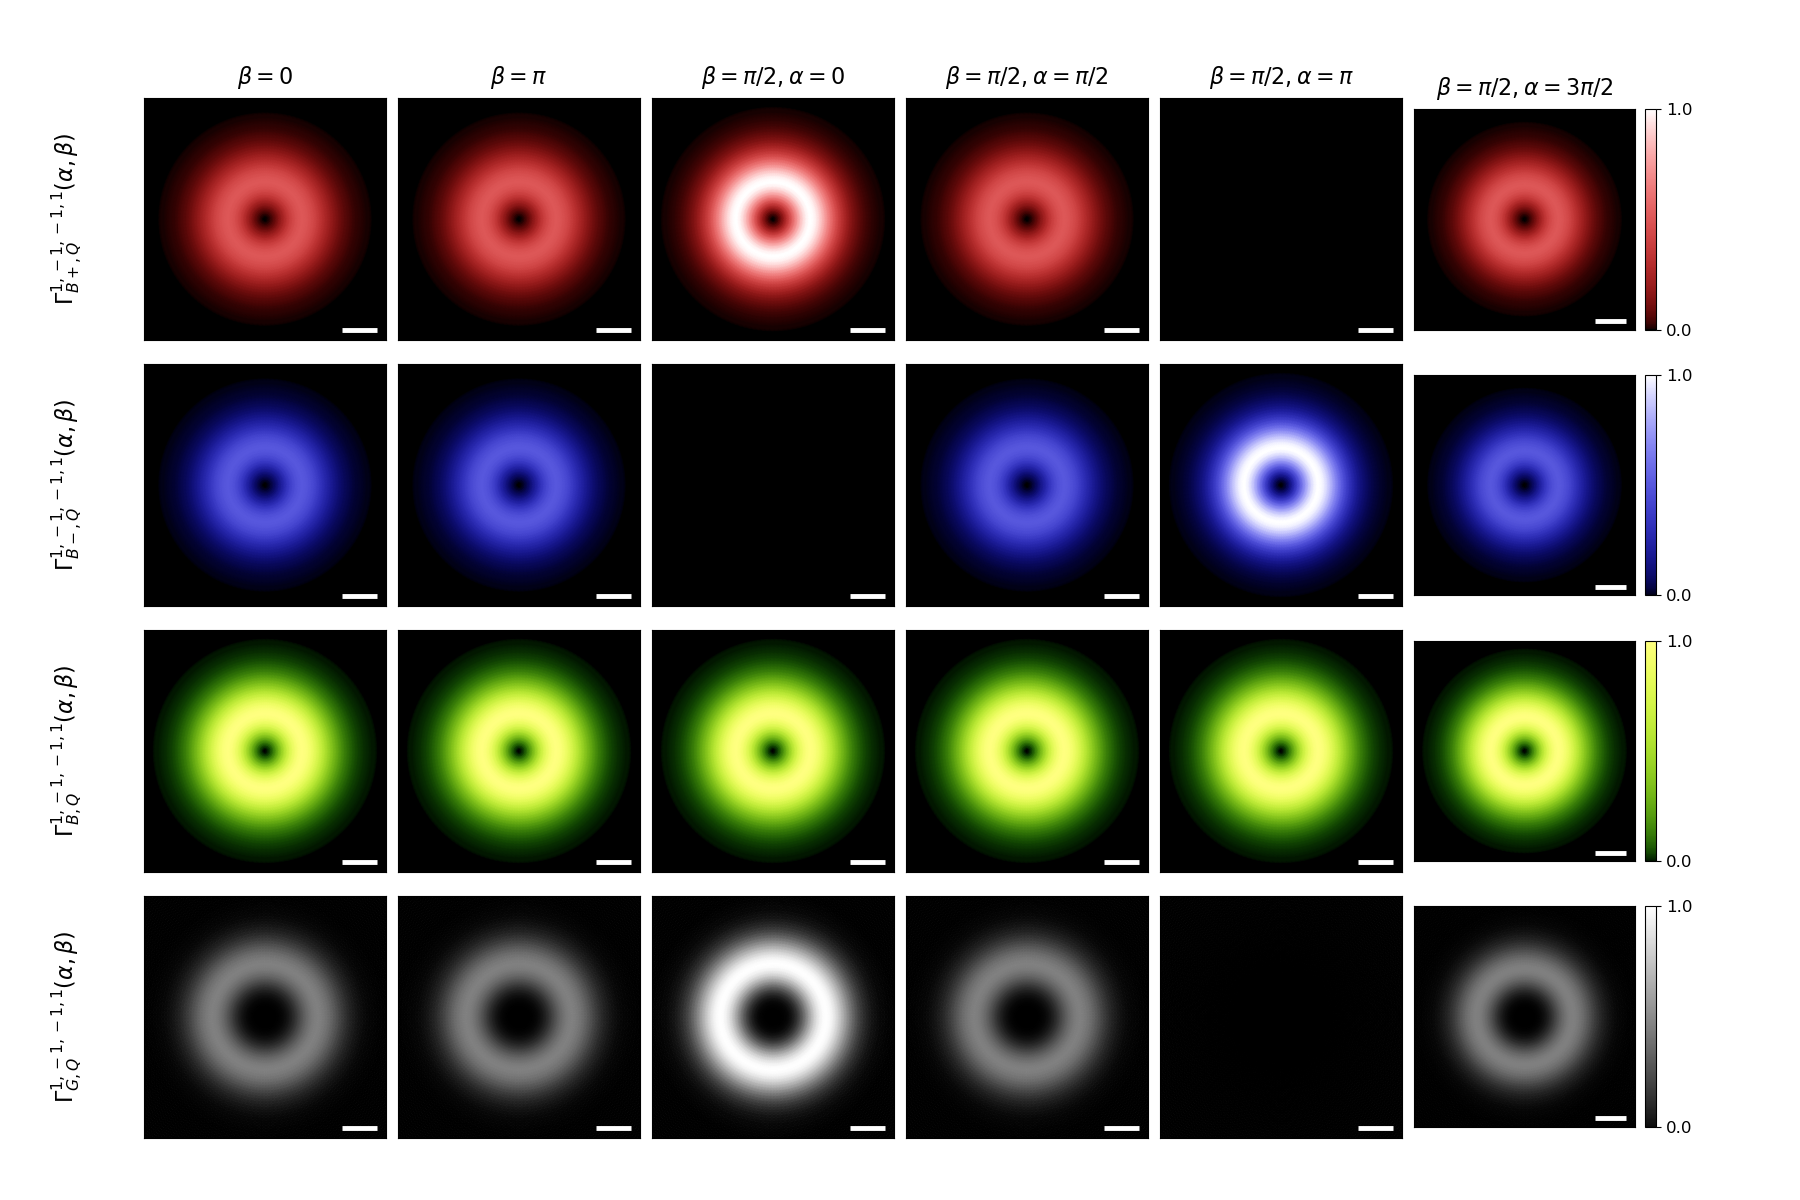

In [17]:
from math import factorial
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ===============================================================
# 1. PARAMETERS & GRID SETUP
# ===============================================================
sigma1, sigma2 = 1, -1
l1, l2 = -1, 1
p = 0
EX = ['B+', 'B-', 'B', 'G']

betalpha = np.array([
    [0, 0], [np.pi, 0], [np.pi/2, 0],
    [np.pi/2, np.pi/2], [np.pi/2, np.pi], [np.pi/2, 3*np.pi/2]
])

titles = [
    r'$\beta = 0$', r'$\beta = \pi$', r'$\beta = \pi/2, \alpha = 0$',
    r'$\beta = \pi/2, \alpha = \pi/2$', r'$\beta = \pi/2, \alpha = \pi$', r'$\beta = \pi/2, \alpha = 3\pi/2$'
]

# Q-space polar grid
Q = np.linspace(0.0001, 1.2 * Q_c, 150)
phiQ = np.linspace(0, 2 * np.pi, 150)
Q_grid, phiQ_grid = np.meshgrid(Q, phiQ)

X = Q_grid * np.cos(phiQ_grid)
Y = Q_grid * np.sin(phiQ_grid)

# ===============================================================
# 2. HELPER FUNCTIONS
# ===============================================================
def F(l, Q_mesh):
    abs_l = abs(l)
    norm = ((-1j)**abs_l * (2 * np.pi) * (a_0 / W) * 
            2**(-1 - abs_l / 2) * np.sqrt(2 * factorial(p) / factorial(abs_l + p) * np.pi))
    return norm * np.exp(-Q_mesh**2 * W**2 / 4) * (W**2) * (Q_mesh * W)**abs_l

# Pre-calculate envelope functions
F_l1 = F(l1, Q_grid)
F_l2 = F(l2, Q_grid)
DJ = int(sigma2 + l2 - sigma1 - l1)

def compute_gamma_map(ex_idx, beta_val, alpha_val):
    A = np.cos(beta_val / 2) * F_l1
    B = np.exp(1j * (DJ * phiQ_grid + alpha_val)) * np.sin(beta_val / 2) * F_l2

    if ex_idx == 0:     # B+
        Z = np.abs(A + B)**2
    elif ex_idx == 1:   # B-
        Z = np.abs(sigma1 * A + sigma2 * B)**2
    elif ex_idx == 2:   # Bright total
        Z = np.abs(A + B)**2 + np.abs(sigma1 * A + sigma2 * B)**2
    elif ex_idx == 3:   # Gray
        Z = ((Q_grid / np.sqrt(Q_grid**2 + q_0**2))**2) * np.abs(A + B)**2

    Z = np.nan_to_num(np.real(Z), nan=0.0, posinf=0.0, neginf=0.0)
    return Z

def get_cmap(ex_idx):
    cmaps = ['colorbarBP', 'colorbarBM', 'colorbarB', 'colorbarG']
    return cmaps[ex_idx]

# ===============================================================
# 3. PLOTTING
# ===============================================================
n_rows, n_cols = len(EX), len(betalpha)
fig, ax = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows), dpi=100)

plot_limit = 0.5 * Q_c / np.sqrt(2)

for ex in range(n_rows):
    # 1. Compute maps and find row maximum for normalization
    row_maps = [compute_gamma_map(ex, betalpha[col, 0], betalpha[col, 1]) for col in range(n_cols)]
    row_max = max(np.max(Z) for Z in row_maps)
    if not np.isfinite(row_max) or row_max < 1e-14:
        row_max = 1.0

    # 2. Render each panel in current row
    for col in range(n_cols):
        ax_curr = ax[ex, col]
        Z_norm = row_maps[col] / row_max

        # Using Gouraud shading to eliminate pcolormesh cell-edge warnings and enable smooth rendering
        mesh = ax_curr.pcolormesh(
            X, Y, Z_norm,
            shading='gouraud',
            vmin=0, vmax=1,
            cmap=get_cmap(ex)
        )

        # Scale bar
        ax_curr.hlines(
            y=-0.46 * Q_c / np.sqrt(2),
            xmin=0.32 * Q_c / np.sqrt(2),
            xmax=0.32 * Q_c / np.sqrt(2) + 0.1 * Q_c,
            color="w", linewidth=3.5, zorder=2
        )

        # Axis styling
        ax_curr.set_xlim(-plot_limit, plot_limit)
        ax_curr.set_ylim(-plot_limit, plot_limit)
        ax_curr.set_xticks([])
        ax_curr.set_yticks([])
        ax_curr.set_aspect("equal")

        # Titles for top row
        if ex == 0:
            ax_curr.set_title(titles[col], fontsize=16, pad=10)

    # 3. Dynamic Colorbar Alignment for each row
    divider = make_axes_locatable(ax[ex, -1])
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mesh, cax=cax, ticks=[0, 1], format="{x:.1f}")
    cbar.ax.tick_params(labelsize=12)

    # 4. Row labels placed using relative axis coordinates
    coeff = f'{sigma1},{l1},{sigma2},{l2}'
    label_text = rf'$\Gamma_{{{EX[ex]},Q}}^{{{coeff}}}(\alpha,\beta)$'
    ax[ex, 0].text(
        -0.25, 0.5, label_text,
        transform=ax[ex, 0].transAxes,
        fontsize=16, va='center', ha='right', rotation=90
    )

# ===============================================================
# 4. LAYOUT ADJUSTMENT
# ===============================================================
fig.subplots_adjust(left=0.08, bottom=0.05, right=0.92, top=0.92, wspace=0.05, hspace=0.08)
plt.show()

# Transition rate (GX, BXs, total BX)

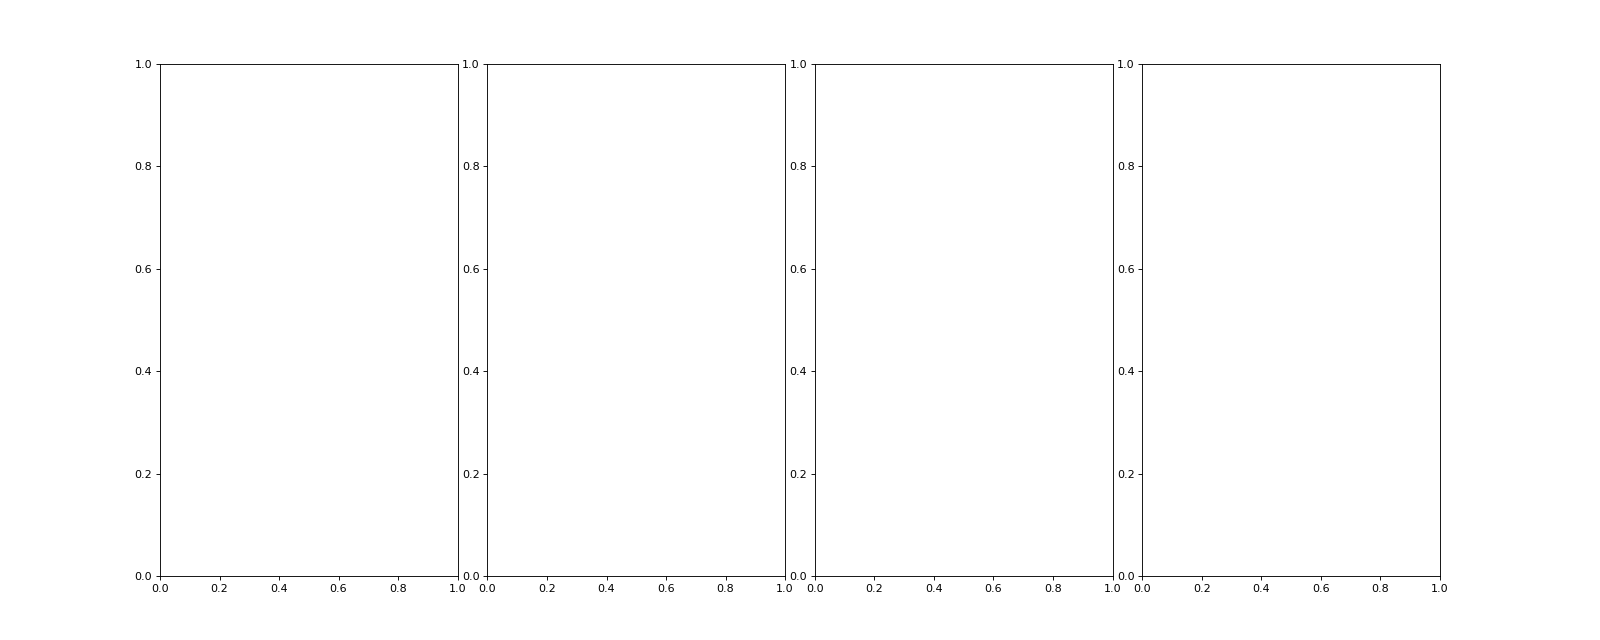

Output()

In [18]:
fig, ax = plt.subplots(1, 4, figsize=(20,8), dpi= 80)

sigma = widgets.Dropdown(options=['1', '-1'], value='1', description='$\sigma$:', disabled=False)
alpha = widgets.FloatSlider(value=0, min=0., max=1, step=1/50 ,description='alpha ($\pi$)')

def constant_of_bright():
    b = (Eg*D_B*a_0 / (2*np.sqrt(2)*hbar))**2
    return b
def constant_of_gray():
    g = (Eg*D_G*a_0 / (2*hbar*W*q))**2 *10**(4)
    return g

def need(sigma):
    ax[0].cla()
    ax[1].cla()
    ax[2].cla()
    ax[3].cla()
    l = np.linspace(-5,5,11)
    sigma1 = int(sigma)
    sigma2 = -int(sigma)
    
    for alpha in [1, 0.5, 0]:
        globals()['BP '+str(alpha)]= []
        globals()['BM '+str(alpha)]= []
        globals()['B '+str(alpha)] = []
        globals()['G '+str(alpha)] = []
        globals()['coolL'+str(alpha)] = []
        coolL = []
        for L in range(-5,6,1):
            l1 = L
            l2 = -L
            if (sigma1+l1-sigma2-l2)==0:
                # print(sigma1, l1, sigma2, l2)
                if (sigma1+l1)==0:
                    coolL += [l1]
                    BP = [(1+ (1-np.sqrt(  np.abs(sigma1+l1)/(np.abs(sigma1+l1)+1)  ))*np.cos(alpha*np.pi))]
                    BM = [(1- (1-np.sqrt(  np.abs(sigma1+l1)/(np.abs(sigma1+l1)+1)  ))*np.cos(alpha*np.pi))]
                    B  = [2/2]
                    G  = [(np.abs(l1)/2+np.abs(l2)/2+1) * (1+ (1-np.sqrt(  np.abs(sigma1+l1)/(np.abs(sigma1+l1)+1)  ))*np.cos(alpha*np.pi))]
                    globals()['BP '+str(alpha)] += BP
                    globals()['coolL'+str(alpha)] += BP
                    globals()['BM '+str(alpha)] += BM       
                    globals()['coolL'+str(alpha)] += BM
                    globals()['B '+str(alpha)]  += B
                    globals()['coolL'+str(alpha)] += B
                    globals()['G '+str(alpha)]  += G
                    globals()['coolL'+str(alpha)] += G

                elif (sigma1+l1)!=0:
                    globals()['BP '+str(alpha)] += [(1+ (-np.sqrt(  np.abs(sigma1+l1)/(np.abs(sigma1+l1)+1)  ))*np.cos(alpha*np.pi))]
                    globals()['BM '+str(alpha)] += [(1- (-np.sqrt(  np.abs(sigma1+l1)/(np.abs(sigma1+l1)+1)  ))*np.cos(alpha*np.pi))]
                    globals()['B '+str(alpha)]  += [2/2]
                    globals()['G '+str(alpha)]  += [(np.abs(l1)/2+np.abs(l2)/2+1) * (1+ (-np.sqrt(  np.abs(sigma1+l1)/(np.abs(sigma1+l1)+1)  ))*np.cos(alpha*np.pi))]
                
            elif (sigma1+l1-sigma2-l2)!=0:
                # print("non:",sigma1, l1, sigma2, l2)
                globals()['BP '+str(alpha)] += [1/1]
                globals()['BM '+str(alpha)] += [1/1]
                globals()['B '+str(alpha)]  += [2/2]
                globals()['G '+str(alpha)]  += [(np.abs(l1)/2+np.abs(l2)/2+1) / (np.abs(0)/2+np.abs(0)/2+1)]
                
        ax[0].plot(l, np.array(globals()['BP '+str(alpha)])+ 9*(1-alpha)*2, color="#0000FFFF", linewidth=0.8, marker = 'o', ms = 8, mec = '#0000FF88', mfc = '#0000FF88', zorder=3)
        ax[1].plot(l, np.array(globals()['BM '+str(alpha)])+ 9*(1-alpha)*2, color="#FF0000FF", linewidth=0.8, marker = 'o', ms = 8, mec = '#FF000088', mfc = '#FF000088', zorder=2) 
        ax[2].plot(l, np.array(globals()['B '+str(alpha)])+ 9*(1-alpha)*2 , color="#15B01AFF", linewidth=0.8, marker = 'o', ms = 8, mec = '#15B01A88', mfc = '#15B01A88', zorder=0) 
        ax[3].plot(l, np.array(globals()['G '+str(alpha)])+ 9*(1-alpha)*2 , color="#000000FF", linewidth=0.8, marker = 'o', ms = 8, mec = '#00000088', mfc = '#00000088', zorder=1)

        ax[0].plot(coolL, globals()['coolL'+str(alpha)][0]+ 9*(1-alpha)*2, marker = 'o', ms = 11, mec = '#000099EE', mfc = '#000099EE', zorder=3)
        ax[1].plot(coolL, globals()['coolL'+str(alpha)][1]+ 9*(1-alpha)*2, marker = 'o', ms = 11, mec = '#990000EE', mfc = '#990000EE', zorder=2) 
        ax[2].plot(coolL, globals()['coolL'+str(alpha)][2]+ 9*(1-alpha)*2, marker = 'o', ms = 11, mec = '#034010EE', mfc = '#034010EE', zorder=0) 
        ax[3].plot(coolL, globals()['coolL'+str(alpha)][3]+ 9*(1-alpha)*2, marker = 'o', ms = 11, mec = '#000000EE', mfc = '#000000EE', zorder=1)

    for i in range(4):
        # for alpha in [1, 0.5, 0]:
            # ax[i].text(2, 6.5+(1-alpha)*16, "α="+str(alpha)+"$\pi$" ,fontsize = 17.5)
        ax[i].set_xlabel('ℓ',fontsize=23)
        ax[i].set_xlim(-5.3,5.3)
        ax[i].set_ylim(-1, 26)
        ax[i].set_xticks(np.arange(-5,6,1))
        ax[i].set_yticks([-1, 0, 2, 4, 6, 8, 9, 11, 13, 15, 17, 18, 20, 22, 24, 26], [' ','0', '2', '4', '6', '8', '0', '2', '4', '6', '8', '0', '2', '4', '6', '8'])
        ax[i].grid(linestyle='-', linewidth=0.2)
        ax[i].hlines(8 , -5.3,5.3, color="k", linewidth=0.7)
        ax[i].hlines(17, -5.3,5.3, color="k", linewidth=0.7)
        ax[i].vlines(0 ,    0, 26, color="k", linewidth=0.13)
    # ax[0].set_title('$\Gamma_{B+}^{'+str(sigma1)+',ℓ,'+str(sigma2)+',-ℓ}(α, \dfrac{\pi}{2})$', fontsize=18)
    # ax[1].set_title('$\Gamma_{B-}^{'+str(sigma1)+',ℓ,'+str(sigma2)+',-ℓ}(α, \dfrac{\pi}{2})$', fontsize=18)
    # ax[2].set_title('$\Gamma_{B}^{'+str(sigma1)+',ℓ,'+str(sigma2)+',-ℓ}(α, \dfrac{\pi}{2}) $', fontsize=18)
    # ax[3].set_title('$\Gamma_{G}^{'+str(sigma1)+',ℓ,'+str(sigma2)+',-ℓ}(α, \dfrac{\pi}{2}) $', fontsize=18)
    plt.suptitle("")

fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.1, hspace=0 )
# plt.tight_layout()
plt.show()
out = widgets.interactive_output(need, {'sigma':sigma})
ui = widgets.VBox([ widgets.Label('polarization:'), widgets.HBox([sigma])])
display(ui , out )